# First clustering pass (historical)

We keep this notebook for the record; the dashboard no longer uses its results.

- **Superseded.** `brewery_clustering_all_runs.ipynb` replaces it. That notebook fits and stores every run of the grid (DBSCAN, HDBSCAN and OPTICS, 1,266 runs over both datasets) in the `allruns_*` tables of `data/clustering_results.db`, and the Spatial Clustering page reads those tables.
- **Uncorrected coordinates.** It ran on the coordinates as stored, before `data/coordinate_corrections.csv` fixed 8 records with swapped latitude and longitude, one longitude with the wrong sign and one misplaced record. The swapped records show up as isolated noise points in the maps below.
- **Deleted tables.** Its `candidate_labels_*` and `selected_labels_*` tables were deleted from `data/clustering_results.db` on 2026-10-30 to keep the file small, so the dashboard no longer uses them. Its other tables are still in the file: the two parameter grids, `algorithm_comparison`, `k_distance_all_records`, `final_model_comparison`, `final_algorithm_summary`, the cluster-size, cluster-geography and noise summaries, the review candidates, and the parameter tables. Their rows were also removed from `saved_results_manifest` and `saved_results_verification`, so both list only tables that exist.
- **Do not re-run the last cell against the project database.** It first drops every table in `data/clustering_results.db`, the `allruns_*` tables included, and then writes its own 44 tables, the label tables among them. The Spatial Clustering page would have no data until `brewery_clustering_all_runs.ipynb` is run again, and the test that checks that the old label tables are gone would fail.
- **Stored outputs** come from an earlier run on another machine (note the Windows paths in the warnings and the save log).

## Settings and data

Imports, the mean Earth radius used to turn km into radians, and the paths of the two analysis databases. The next two cells load both datasets and keep records with valid coordinates. None is removed (9,488 and 9,487 records). Coordinates go to scikit-learn in radians, with the Haversine metric.

In [1]:
# %% Imports and settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sqlalchemy import create_engine
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, HDBSCAN

from geographic_utils import haversine_km

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

EARTH_RADIUS_KM = 6371.0088
DB_PATH = "data/analysis_all_records.db"
UNIQUE_DB_PATH = "data/analysis_unique_records.db"

In [2]:
# %% Load source datasets
# If your SQLite database/table paths differ, change DB_PATH / UNIQUE_DB_PATH.
engine_all = create_engine(f"sqlite:///{DB_PATH}")
analysis_all_records = pd.read_sql(
    "SELECT * FROM analysis_all_records", con=engine_all
)
engine_all.dispose()

engine_unique = create_engine(f"sqlite:///{UNIQUE_DB_PATH}")
analysis_unique_records = pd.read_sql(
    "SELECT * FROM analysis_unique_records", con=engine_unique
)
engine_unique.dispose()

print("All-record dataset:")
analysis_all_records.info()
print("\nUnique-record dataset:")
analysis_unique_records.info()

All-record dataset:
<class 'pandas.DataFrame'>
RangeIndex: 9488 entries, 0 to 9487
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              9488 non-null   str    
 1   name            9488 non-null   str    
 2   brewery_type    9488 non-null   str    
 3   address_1       9340 non-null   str    
 4   address_2       322 non-null    str    
 5   address_3       38 non-null     str    
 6   city            9488 non-null   str    
 7   state_province  9488 non-null   str    
 8   postal_code     9487 non-null   str    
 9   country         9488 non-null   str    
 10  longitude       9488 non-null   float64
 11  latitude        9488 non-null   float64
 12  phone           8565 non-null   str    
 13  website_url     8631 non-null   str    
 14  state           9488 non-null   str    
 15  street          9340 non-null   str    
dtypes: float64(2), str(14)
memory usage: 2.8 MB

Unique-record dataset:
<

In [3]:
# %% Prepare datasets for clustering
# all_records: every retained record counts.
# unique_records: the records in your separately prepared unique dataset.
clustering_datasets = {
    "all_records": analysis_all_records.copy(),
    "unique_records": analysis_unique_records.copy(),
}

required_coordinate_columns = {"latitude", "longitude"}
for dataset_name, df in clustering_datasets.items():
    missing_columns = required_coordinate_columns - set(df.columns)
    if missing_columns:
        raise KeyError(
            f"{dataset_name} is missing required columns: {sorted(missing_columns)}"
        )

    # Haversine distance requires [latitude, longitude] in radians.
    df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
    valid_coordinates = (
        df["latitude"].between(-90, 90)
        & df["longitude"].between(-180, 180)
        & df["latitude"].notna()
        & df["longitude"].notna()
    )
    invalid_count = int((~valid_coordinates).sum())
    if invalid_count:
        print(
            f"WARNING: {dataset_name}: removing {invalid_count:,} records "
            "with missing or invalid coordinates for clustering."
        )
    df = df.loc[valid_coordinates].copy()
    df["latitude_rad"] = np.radians(df["latitude"])
    df["longitude_rad"] = np.radians(df["longitude"])
    clustering_datasets[dataset_name] = df.reset_index(drop=True)

for dataset_name, df in clustering_datasets.items():
    print(f"{dataset_name}: {len(df):,} valid-coordinate records")



all_records: 9,488 valid-coordinate records
unique_records: 9,487 valid-coordinate records


## Parameter grids

DBSCAN: radii (`eps`) from 25 to 520 km, each combined with every `min_samples` value from 4 to 32. HDBSCAN: `min_cluster_size` from 5 to 520, each combined with every `min_samples` value plus `None` (scikit-learn then uses `min_cluster_size`). That makes 264 DBSCAN and 336 HDBSCAN runs per dataset. The all-runs notebook uses the same grid.

In [4]:
# %% Candidate parameters
# Original DBSCAN eps list contained duplicate values 280 and 300 appeared
# in a non-sorted order; the list below preserves all DISTINCT values and
# sorts them ascending. No unique eps values have been removed.
# Original list: [25, 30, 35, 40, 45, 50, 55, 60, 80, 100, 120, 140,
# 160, 180, 200, 220, 240, 300, 280, 320, 400, 480, 500, 520]
# There were no exact duplicate eps values in that original list; sorting
# simply makes plots and tables easier to read.
# Correction to the note above: the eps list has no duplicates; 280 and 300 were only out of order.
candidate_eps_km = sorted(set([
    25, 30, 35, 40, 45, 50, 55, 60, 80, 100, 120, 140,
    160, 180, 200, 220, 240, 300, 280, 320, 400, 480, 500, 520
]))

# All original distinct min_samples values are preserved.
candidate_min_samples = sorted(set([4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 32]))

# Original HDBSCAN list repeated 30 and 50. Duplicates are removed because
# repeating a parameter combination does not create a new experiment.
# All distinct values from the original list are preserved.
candidate_min_cluster_sizes = sorted(set([
    5, 10, 15, 20, 30, 50, 25, 30, 35, 40, 45, 50, 55, 60,
    80, 100, 120, 140, 160, 180, 200, 220, 240, 300, 280, 320,
    400, 480, 500, 520
]))

# None is intentionally retained as an HDBSCAN min_samples option.
candidate_hdbscan_min_samples = [None] + sorted(set([
    4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 32
]))

print("DBSCAN eps values (km):", candidate_eps_km)
print("DBSCAN min_samples:", candidate_min_samples)
print("HDBSCAN min_cluster_size:", candidate_min_cluster_sizes)
print("HDBSCAN min_samples:", candidate_hdbscan_min_samples)


DBSCAN eps values (km): [25, 30, 35, 40, 45, 50, 55, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 280, 300, 320, 400, 480, 500, 520]
DBSCAN min_samples: [4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 32]
HDBSCAN min_cluster_size: [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 280, 300, 320, 400, 480, 500, 520]
HDBSCAN min_samples: [None, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 32]


## k-distance curves

For each `min_samples` value we take the distance from every point to its `min_samples`-th nearest neighbour (the point itself counts) and sort it. A knee in this curve is the usual first guess for `eps`. Here the curves stay low for most points and rise steeply only at the very end, so they suggest no single radius; the tail is isolated breweries, the swapped records among them. All distances are saved in `k_distance_all_records` (208,725 rows; despite the name it holds both datasets).

In [5]:
# %% K-distance analysis
# DBSCAN min_samples includes the point itself. With n_neighbors=min_samples,
# the last distance column is the distance to that neighbor rank.
k_distance_results = {}
for dataset_name, df in clustering_datasets.items():
    coordinates_rad = df[["latitude_rad", "longitude_rad"]].to_numpy()
    dataset_results = {}
    for min_samples in candidate_min_samples:
        if len(coordinates_rad) < min_samples:
            print(
                f"Skipping k-distance min_samples={min_samples} for "
                f"{dataset_name}: only {len(coordinates_rad)} rows."
            )
            continue
        nearest_neighbors = NearestNeighbors(
            n_neighbors=min_samples, metric="haversine"
        )
        nearest_neighbors.fit(coordinates_rad)
        distances, _ = nearest_neighbors.kneighbors(coordinates_rad)
        # Haversine distances come back in radians; multiplying by the Earth radius gives km.
        sorted_distances_km = np.sort(distances[:, -1] * EARTH_RADIUS_KM)
        dataset_results[min_samples] = sorted_distances_km
    k_distance_results[dataset_name] = dataset_results

print("K-distance calculations completed.")


K-distance calculations completed.


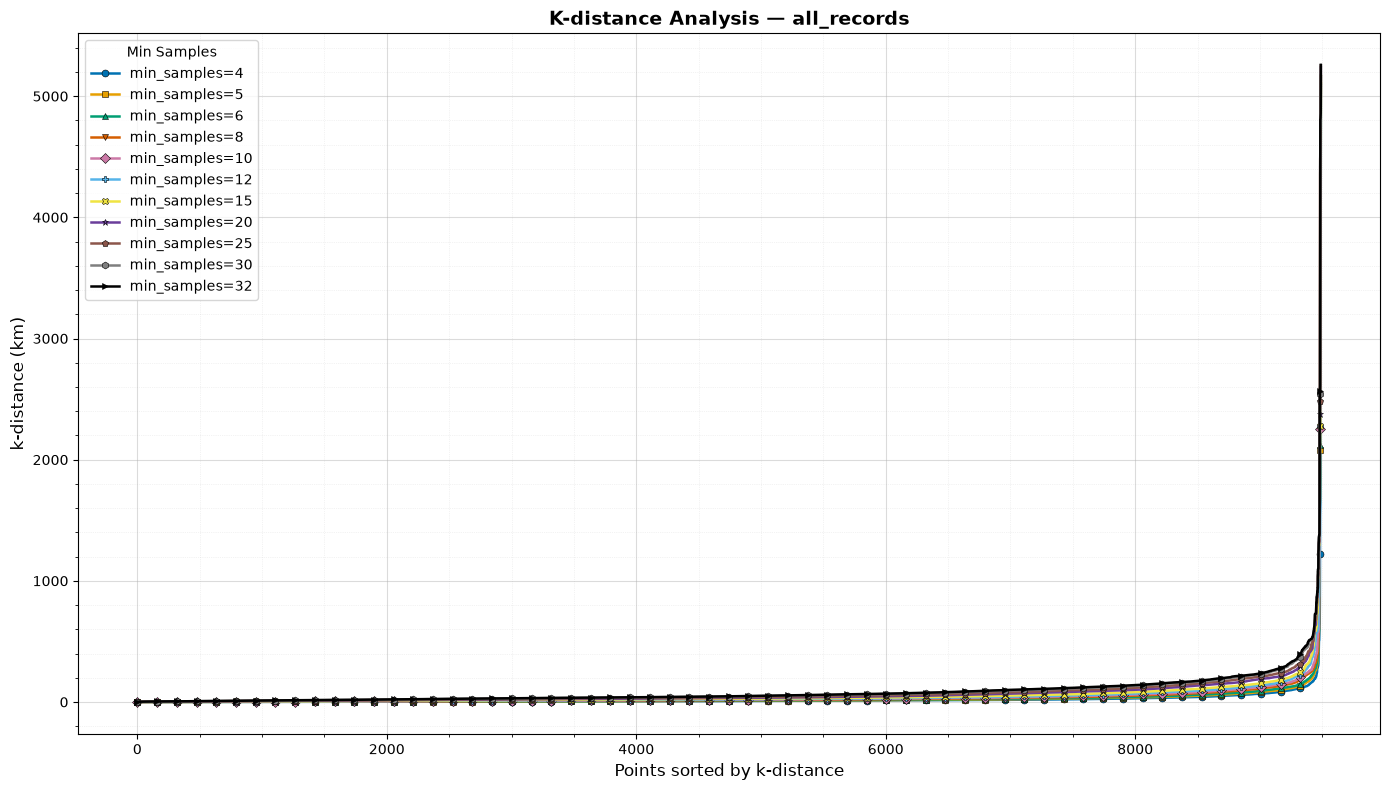

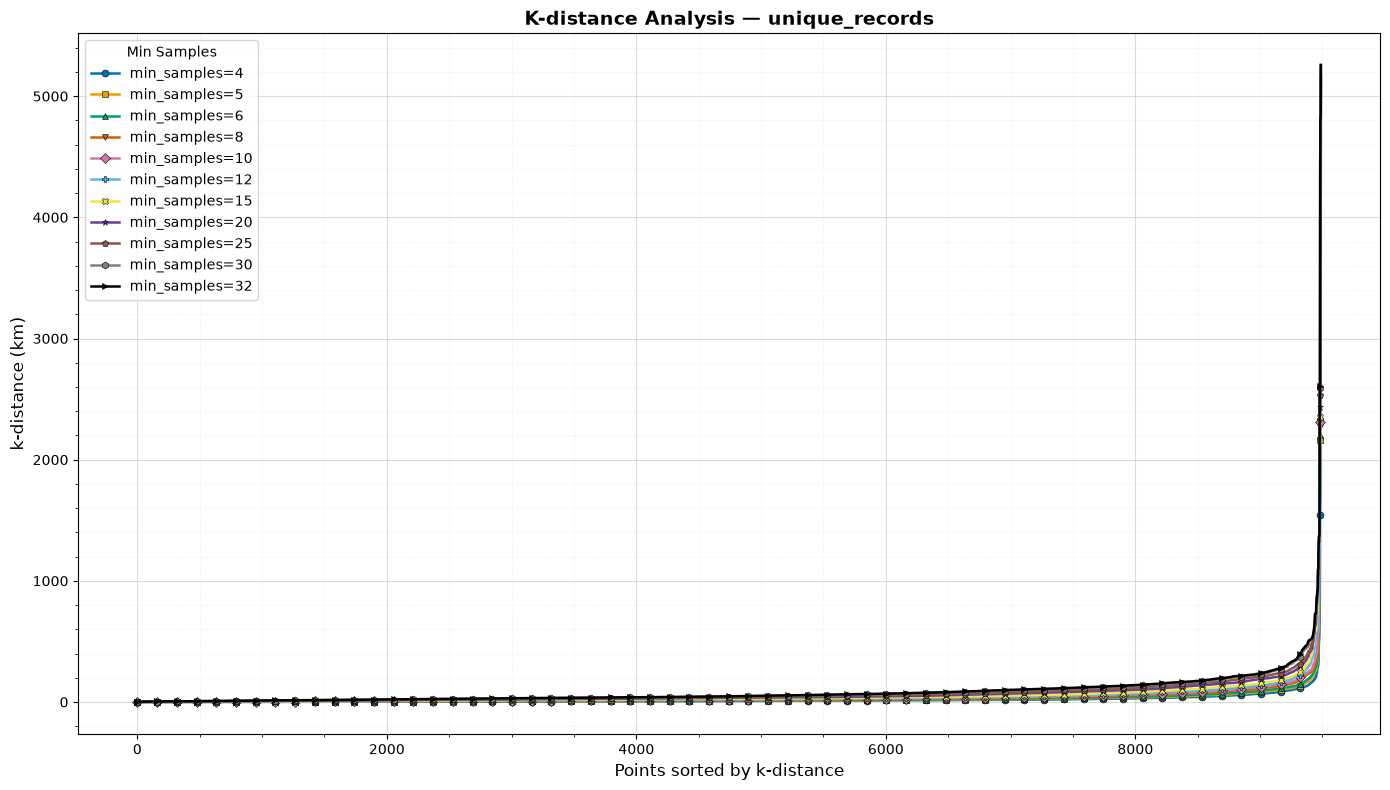

In [6]:
# %% Plot k-distance curves
plot_colors = [
    "#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7",
    "#56B4E9", "#F0E442", "#6A3D9A", "#8C564B", "#7F7F7F", "#000000",
]
plot_markers = ["o", "s", "^", "v", "D", "P", "X", "*", "p", "h", ">"]

for dataset_name, dataset_results in k_distance_results.items():
    fig, ax = plt.subplots(figsize=(14, 8))
    for i, (min_samples, distances_km) in enumerate(dataset_results.items()):
        x = np.arange(1, len(distances_km) + 1)
        ax.plot(
            x, distances_km,
            color=plot_colors[i % len(plot_colors)], linewidth=1.8,
            marker=plot_markers[i % len(plot_markers)], markersize=5,
            markevery=max(1, len(distances_km) // 60),
            markeredgecolor="black", markeredgewidth=0.4,
            label=f"min_samples={min_samples}",
        )
    ax.set_xlabel("Points sorted by k-distance", fontsize=12)
    ax.set_ylabel("k-distance (km)", fontsize=12)
    ax.set_title(f"K-distance Analysis — {dataset_name}", fontsize=14, fontweight="bold")
    ax.minorticks_on()
    ax.grid(which="major", linestyle="-", linewidth=0.8, alpha=0.45)
    ax.grid(which="minor", linestyle=":", linewidth=0.5, alpha=0.3)
    ax.legend(title="Min Samples")
    fig.tight_layout()
    plt.show()


## DBSCAN grid

We fit every `eps` and `min_samples` pair on both datasets and record the cluster count, the noise share and the cluster sizes.

In [7]:
# %% DBSCAN parameter grid
# One complete experiment table is used (instead of running an almost
# identical grid twice under dbscan_parameter_results and dbscan_results).
dbscan_results = {}
for dataset_name, df in clustering_datasets.items():
    coordinates_rad = df[["latitude_rad", "longitude_rad"]].to_numpy()
    total_records = len(df)
    results = []
    for eps_km in candidate_eps_km:
        eps_radians = eps_km / EARTH_RADIUS_KM
        for min_samples in candidate_min_samples:
            if total_records < min_samples:
                continue
            model = DBSCAN(
                eps=eps_radians, min_samples=min_samples, metric="haversine"
            )
            labels = model.fit_predict(coordinates_rad)
            noise_mask = labels == -1
            noise_records = int(noise_mask.sum())
            clustered_records = total_records - noise_records
            cluster_sizes = pd.Series(labels[~noise_mask]).value_counts()
            cluster_count = int(cluster_sizes.size)
            largest_cluster_size = int(cluster_sizes.max()) if cluster_count else 0
            smallest_cluster_size = int(cluster_sizes.min()) if cluster_count else 0
            median_cluster_size = float(cluster_sizes.median()) if cluster_count else np.nan
            results.append({
                "dataset": dataset_name,
                "eps_km": eps_km,
                "min_cluster_size": np.nan,
                "min_samples": min_samples,
                "cluster_count": cluster_count,
                "clustered_records": clustered_records,
                "clustered_share_pct": clustered_records / total_records * 100,
                "noise_records": noise_records,
                "noise_share_pct": noise_records / total_records * 100,
                "largest_cluster_size": largest_cluster_size,
                "largest_cluster_share_pct": largest_cluster_size / total_records * 100,
                "smallest_cluster_size": smallest_cluster_size,
                "median_cluster_size": median_cluster_size,
            })
    dbscan_results[dataset_name] = pd.DataFrame(results)

print("DBSCAN parameter experiments completed.")


DBSCAN parameter experiments completed.


In [8]:
dbscan_results['all_records']

,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,all_records,25,NaN,4,289,7986,84.169477,1502,15.830523,948,9.991568,3,7.0
1,all_records,25,NaN,5,221,7639,80.512226,1849,19.487774,930,9.801855,3,11.0
2,all_records,25,NaN,6,195,7391,77.898398,2097,22.101602,890,9.380270,3,13.0
3,all_records,25,NaN,8,160,6975,73.513912,2513,26.486088,869,9.158938,4,17.0
4,all_records,25,NaN,10,133,6592,69.477234,2896,30.522766,843,8.884907,10,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,all_records,520,NaN,15,11,9440,99.494098,48,0.505902,6111,64.407673,33,61.0
260,all_records,520,NaN,20,11,9440,99.494098,48,0.505902,6111,64.407673,33,61.0
261,all_records,520,NaN,25,11,9440,99.494098,48,0.505902,6111,64.407673,33,61.0
262,all_records,520,NaN,30,11,9440,99.494098,48,0.505902,6111,64.407673,33,61.0


In [9]:
dbscan_results['unique_records']

,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,unique_records,25,NaN,4,289,7985,84.167809,1502,15.832191,947,9.982081,3,7.0
1,unique_records,25,NaN,5,221,7638,80.510172,1849,19.489828,929,9.792347,3,11.0
2,unique_records,25,NaN,6,195,7390,77.896068,2097,22.103932,889,9.370718,3,13.0
3,unique_records,25,NaN,8,160,6974,73.511120,2513,26.488880,868,9.149362,4,17.0
4,unique_records,25,NaN,10,133,6591,69.474017,2896,30.525983,842,8.875303,10,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,unique_records,520,NaN,15,11,9439,99.494044,48,0.505956,6111,64.414462,33,61.0
260,unique_records,520,NaN,20,11,9439,99.494044,48,0.505956,6111,64.414462,33,61.0
261,unique_records,520,NaN,25,11,9439,99.494044,48,0.505956,6111,64.414462,33,61.0
262,unique_records,520,NaN,30,11,9439,99.494044,48,0.505956,6111,64.414462,33,61.0


In [10]:
# %% Inspect DBSCAN experiment results
for dataset_name, results in dbscan_results.items():
    print(f"\nDBSCAN — {dataset_name}")
    display(results.sort_values(["min_samples", "eps_km"]).reset_index(drop=True).round(2))




DBSCAN — all_records


,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,all_records,25,NaN,4,289,7986,84.17,1502,15.83,948,9.99,3,7.0
1,all_records,30,NaN,4,256,8233,86.77,1255,13.23,1785,18.81,4,8.0
2,all_records,35,NaN,4,244,8487,89.45,1001,10.55,1918,20.22,3,9.0
3,all_records,40,NaN,4,218,8649,91.16,839,8.84,1955,20.60,3,9.0
4,all_records,45,NaN,4,189,8764,92.37,724,7.63,2016,21.25,3,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,all_records,320,NaN,32,14,9414,99.22,74,0.78,6107,64.37,33,57.5
260,all_records,400,NaN,32,14,9432,99.41,56,0.59,6111,64.41,33,60.0
261,all_records,480,NaN,32,13,9437,99.46,51,0.54,6111,64.41,33,61.0
262,all_records,500,NaN,32,13,9437,99.46,51,0.54,6111,64.41,33,54.0



DBSCAN — unique_records


,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,unique_records,25,NaN,4,289,7985,84.17,1502,15.83,947,9.98,3,7.0
1,unique_records,30,NaN,4,256,8232,86.77,1255,13.23,1784,18.80,4,8.0
2,unique_records,35,NaN,4,244,8486,89.45,1001,10.55,1917,20.21,3,9.0
3,unique_records,40,NaN,4,218,8648,91.16,839,8.84,1954,20.60,3,9.0
4,unique_records,45,NaN,4,189,8763,92.37,724,7.63,2015,21.24,3,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
259,unique_records,320,NaN,32,14,9413,99.22,74,0.78,6107,64.37,33,57.5
260,unique_records,400,NaN,32,14,9431,99.41,56,0.59,6111,64.41,33,60.0
261,unique_records,480,NaN,32,13,9436,99.46,51,0.54,6111,64.41,33,61.0
262,unique_records,500,NaN,32,13,9436,99.46,51,0.54,6111,64.41,33,54.0


At the small end (25 km, `min_samples` 4) DBSCAN finds 289 clusters and leaves 15.83% of records as noise. At 520 km noise falls to 0.51% and one cluster holds 64.41% of all records. Some clusters are smaller than `min_samples` (3 records with `min_samples` 4): a border point stays with the first cluster that reaches it, so a later cluster can lose border points. The two datasets give almost identical tables. The next two plots show cluster count and noise share against `eps`.

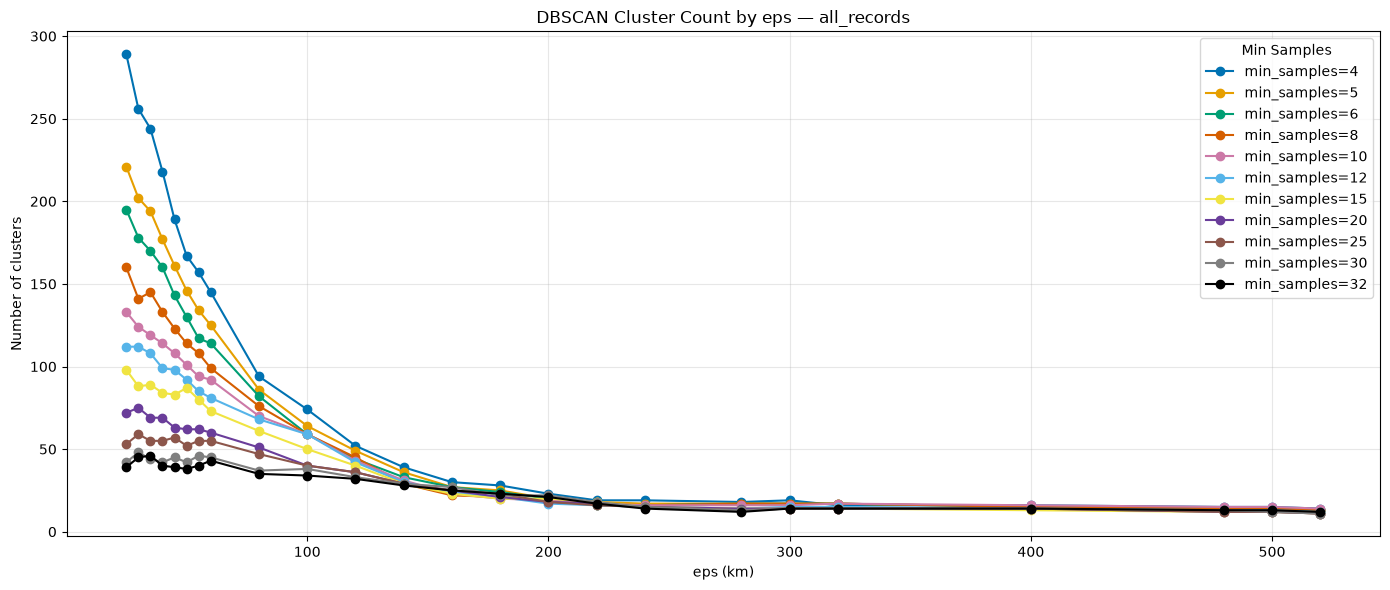

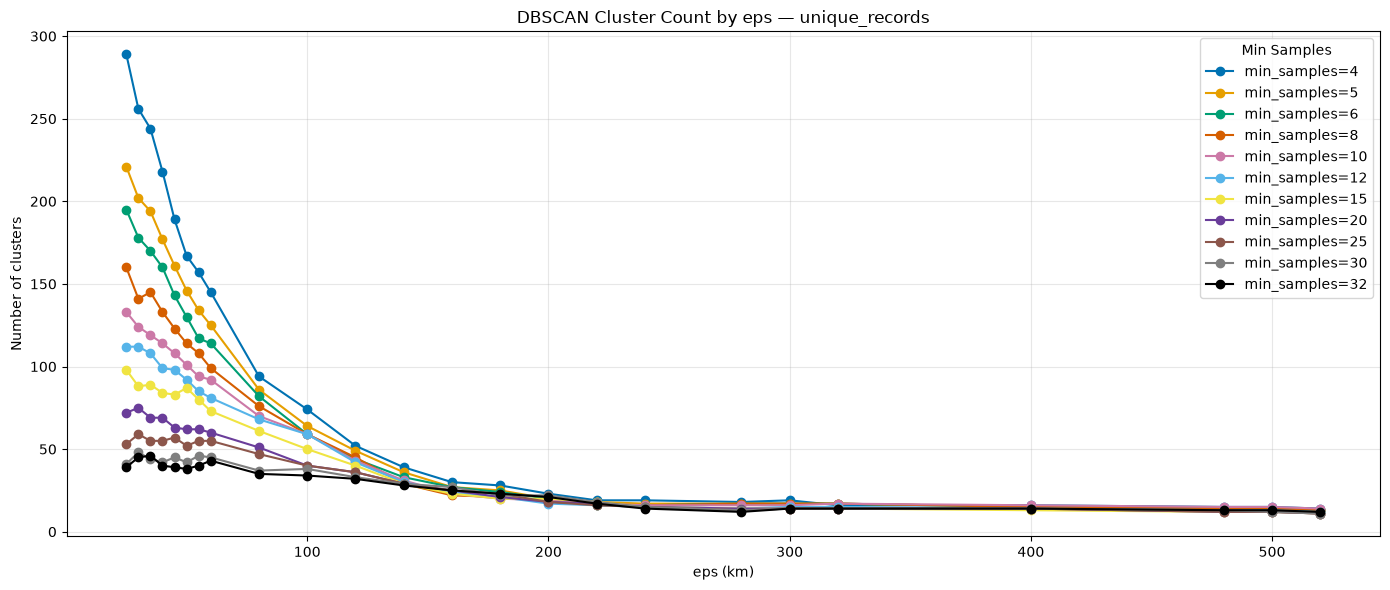

In [11]:
# %% DBSCAN parameter plots: cluster count
for dataset_name, results in dbscan_results.items():
    fig, ax = plt.subplots(figsize=(14, 6))
    for i, min_samples in enumerate(candidate_min_samples):
        subset = results[results["min_samples"] == min_samples].sort_values("eps_km")
        if subset.empty:
            continue
        ax.plot(subset["eps_km"], subset["cluster_count"], color=plot_colors[i % len(plot_colors)], marker="o", label=f"min_samples={min_samples}")
    ax.set_xlabel("eps (km)")
    ax.set_ylabel("Number of clusters")
    ax.set_title(f"DBSCAN Cluster Count by eps — {dataset_name}")
    ax.legend(title="Min Samples")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


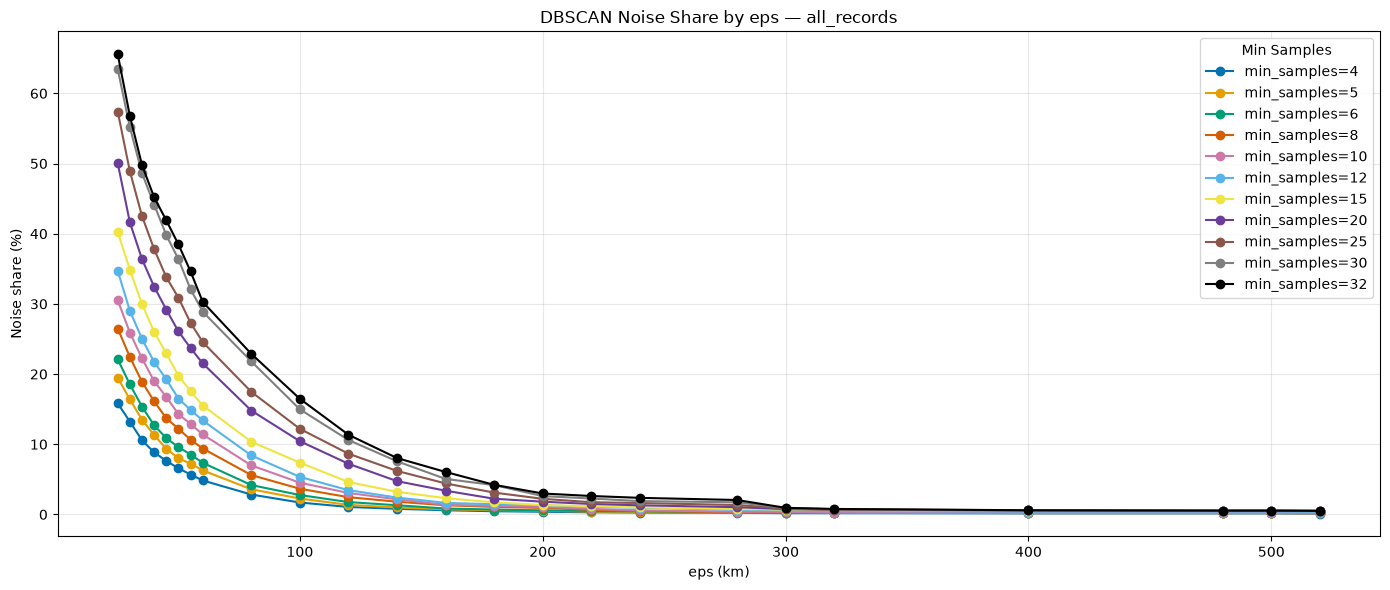

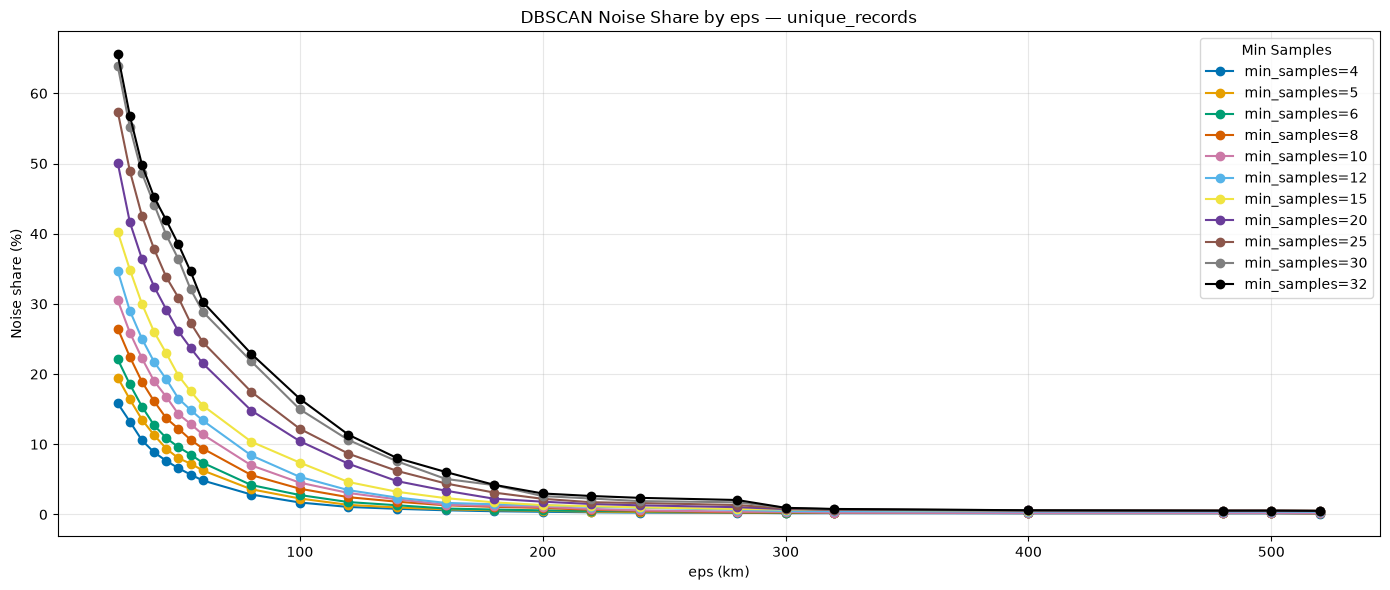

In [12]:
# %% DBSCAN parameter plots: noise share
for dataset_name, results in dbscan_results.items():
    fig, ax = plt.subplots(figsize=(14, 6))
    for i, min_samples in enumerate(candidate_min_samples):
        subset = results[results["min_samples"] == min_samples].sort_values("eps_km")
        if subset.empty:
            continue
        ax.plot(subset["eps_km"], subset["noise_share_pct"], color=plot_colors[i % len(plot_colors)], marker="o", label=f"min_samples={min_samples}")
    ax.set_xlabel("eps (km)")
    ax.set_ylabel("Noise share (%)")
    ax.set_title(f"DBSCAN Noise Share by eps — {dataset_name}")
    ax.legend(title="Min Samples")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


## Screening flags

Each run is flagged for too few clusters, very high noise, one dominant cluster or very many clusters. `review_candidate` only means that no flag fired; it is not a quality score.

In [13]:
# %% DBSCAN diagnostics
# These are screening flags, not automatic model-quality judgments.
# The combined table further down recomputes these flags for both algorithms.
def classify_dbscan_result(row):
    warnings = []
    if row["cluster_count"] <= 1:
        warnings.append("too_few_clusters")
    if row["noise_share_pct"] >= 80:
        warnings.append("very_high_noise")
    if row["largest_cluster_share_pct"] >= 80:
        warnings.append("dominant_cluster")
    if row["cluster_count"] >= 100:
        warnings.append("many_small_clusters")
    return "; ".join(warnings) if warnings else "review_candidate"

for dataset_name, results in dbscan_results.items():
    results["diagnostic"] = results.apply(classify_dbscan_result, axis=1)
    dbscan_results[dataset_name] = results
    print(f"\nDBSCAN screening — {dataset_name}")
    display(results[[
        "eps_km", "min_samples", "cluster_count", "clustered_share_pct",
        "noise_share_pct", "largest_cluster_share_pct", "median_cluster_size", "diagnostic"
    ]].round(2))



DBSCAN screening — all_records


,eps_km,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size,diagnostic
0,25,4,289,84.17,15.83,9.99,7.0,many_small_clusters
1,25,5,221,80.51,19.49,9.80,11.0,many_small_clusters
2,25,6,195,77.90,22.10,9.38,13.0,many_small_clusters
3,25,8,160,73.51,26.49,9.16,17.0,many_small_clusters
4,25,10,133,69.48,30.52,8.88,20.0,many_small_clusters
...,...,...,...,...,...,...,...,...
259,520,15,11,99.49,0.51,64.41,61.0,review_candidate
260,520,20,11,99.49,0.51,64.41,61.0,review_candidate
261,520,25,11,99.49,0.51,64.41,61.0,review_candidate
262,520,30,11,99.49,0.51,64.41,61.0,review_candidate



DBSCAN screening — unique_records


,eps_km,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size,diagnostic
0,25,4,289,84.17,15.83,9.98,7.0,many_small_clusters
1,25,5,221,80.51,19.49,9.79,11.0,many_small_clusters
2,25,6,195,77.90,22.10,9.37,13.0,many_small_clusters
3,25,8,160,73.51,26.49,9.15,17.0,many_small_clusters
4,25,10,133,69.47,30.53,8.88,20.0,many_small_clusters
...,...,...,...,...,...,...,...,...
259,520,15,11,99.49,0.51,64.41,61.0,review_candidate
260,520,20,11,99.49,0.51,64.41,61.0,review_candidate
261,520,25,11,99.49,0.51,64.41,61.0,review_candidate
262,520,30,11,99.49,0.51,64.41,61.0,review_candidate


## HDBSCAN grid

The same metrics for every `min_cluster_size` and `min_samples` pair.

In [14]:
# %% HDBSCAN parameter grid
hdbscan_parameter_results = {}
for dataset_name, df in clustering_datasets.items():
    coordinates_rad = df[["latitude_rad", "longitude_rad"]].to_numpy()
    total_records = len(df)
    results = []
    for min_cluster_size in candidate_min_cluster_sizes:
        for min_samples in candidate_hdbscan_min_samples:
            # min_samples=None is a valid HDBSCAN option and means the
            # min_cluster_size value is used for the relevant default.
            # scikit-learn's HDBSCAN; the all-runs notebook uses the hdbscan library instead.
            model = HDBSCAN(
                min_cluster_size=min_cluster_size,
                min_samples=min_samples,
                metric="haversine",
                algorithm="auto",
                copy=True,
            )
            labels = model.fit_predict(coordinates_rad)
            noise_mask = labels == -1
            noise_records = int(noise_mask.sum())
            clustered_records = total_records - noise_records
            cluster_sizes = pd.Series(labels[~noise_mask]).value_counts()
            cluster_count = int(cluster_sizes.size)
            largest_cluster_size = int(cluster_sizes.max()) if cluster_count else 0
            smallest_cluster_size = int(cluster_sizes.min()) if cluster_count else 0
            median_cluster_size = float(cluster_sizes.median()) if cluster_count else np.nan
            results.append({
                "dataset": dataset_name,
                "eps_km": np.nan,
                "min_cluster_size": min_cluster_size,
                "min_samples": min_samples,
                "cluster_count": cluster_count,
                "clustered_records": clustered_records,
                "clustered_share_pct": clustered_records / total_records * 100,
                "noise_records": noise_records,
                "noise_share_pct": noise_records / total_records * 100,
                "largest_cluster_size": largest_cluster_size,
                "largest_cluster_share_pct": largest_cluster_size / total_records * 100,
                "smallest_cluster_size": smallest_cluster_size,
                "median_cluster_size": median_cluster_size,
            })
    hdbscan_parameter_results[dataset_name] = pd.DataFrame(results)

print("HDBSCAN parameter experiments completed.")


HDBSCAN parameter experiments completed.


In [15]:
hdbscan_parameter_results['all_records']

,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,all_records,NaN,5,NaN,560,6441,67.885750,3047,32.114250,67,0.706155,5,9.0
1,all_records,NaN,5,4.0,609,6837,72.059444,2651,27.940556,77,0.811551,5,9.0
2,all_records,NaN,5,5.0,560,6441,67.885750,3047,32.114250,67,0.706155,5,9.0
3,all_records,NaN,5,6.0,434,6435,67.822513,3053,32.177487,164,1.728499,5,11.0
4,all_records,NaN,5,8.0,313,6168,65.008432,3320,34.991568,113,1.190978,5,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,all_records,NaN,520,15.0,4,9179,96.743255,309,3.256745,3607,38.016442,861,2355.5
332,all_records,NaN,520,20.0,5,8562,90.240304,926,9.759696,3621,38.163997,861,900.0
333,all_records,NaN,520,25.0,5,8552,90.134907,936,9.865093,3622,38.174536,858,901.0
334,all_records,NaN,520,30.0,5,8529,89.892496,959,10.107504,3614,38.090219,844,900.0


In [16]:
hdbscan_parameter_results['unique_records']

,dataset,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,unique_records,NaN,5,NaN,559,6414,67.608306,3073,32.391694,67,0.706230,5,8.0
1,unique_records,NaN,5,4.0,609,6862,72.330558,2625,27.669442,77,0.811637,5,9.0
2,unique_records,NaN,5,5.0,559,6414,67.608306,3073,32.391694,67,0.706230,5,8.0
3,unique_records,NaN,5,6.0,433,6440,67.882365,3047,32.117635,164,1.728681,5,11.0
4,unique_records,NaN,5,8.0,312,6201,65.363128,3286,34.636872,114,1.201644,5,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,unique_records,NaN,520,15.0,4,9177,96.732371,310,3.267629,3607,38.020449,860,2355.0
332,unique_records,NaN,520,20.0,5,8559,90.218193,928,9.781807,3620,38.157479,860,900.0
333,unique_records,NaN,520,25.0,5,8552,90.144408,935,9.855592,3623,38.189101,858,901.0
334,unique_records,NaN,520,30.0,5,8527,89.880890,960,10.119110,3614,38.094234,844,900.0


In [17]:
# %% Inspect HDBSCAN results
comparison_columns = [
    "min_cluster_size", "min_samples", "cluster_count", "clustered_share_pct",
    "noise_share_pct", "largest_cluster_share_pct", "median_cluster_size"
]
for dataset_name, results in hdbscan_parameter_results.items():
    print(f"\nHDBSCAN — {dataset_name}")
    display(results[comparison_columns].sort_values(
        ["min_cluster_size", "min_samples"], na_position="first"
    ).reset_index(drop=True).round(2))



HDBSCAN — all_records


,min_cluster_size,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size
0,5,NaN,560,67.89,32.11,0.71,9.0
1,5,4.0,609,72.06,27.94,0.81,9.0
2,5,5.0,560,67.89,32.11,0.71,9.0
3,5,6.0,434,67.82,32.18,1.73,11.0
4,5,8.0,313,65.01,34.99,1.19,15.0
...,...,...,...,...,...,...,...
331,520,15.0,4,96.74,3.26,38.02,2355.5
332,520,20.0,5,90.24,9.76,38.16,900.0
333,520,25.0,5,90.13,9.87,38.17,901.0
334,520,30.0,5,89.89,10.11,38.09,900.0



HDBSCAN — unique_records


,min_cluster_size,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size
0,5,NaN,559,67.61,32.39,0.71,8.0
1,5,4.0,609,72.33,27.67,0.81,9.0
2,5,5.0,559,67.61,32.39,0.71,8.0
3,5,6.0,433,67.88,32.12,1.73,11.0
4,5,8.0,312,65.36,34.64,1.20,15.0
...,...,...,...,...,...,...,...
331,520,15.0,4,96.73,3.27,38.02,2355.0
332,520,20.0,5,90.22,9.78,38.16,900.0
333,520,25.0,5,90.14,9.86,38.19,901.0
334,520,30.0,5,89.88,10.12,38.09,900.0


With `min_cluster_size` 5, `min_samples` None and 5 give identical results (560 clusters, 32.11% noise for all records), since None falls back to `min_cluster_size`. Larger `min_cluster_size` values give fewer, bigger clusters; at 520 the map splits into 4 or 5 clusters. The plots below show cluster count and noise share for every combination.

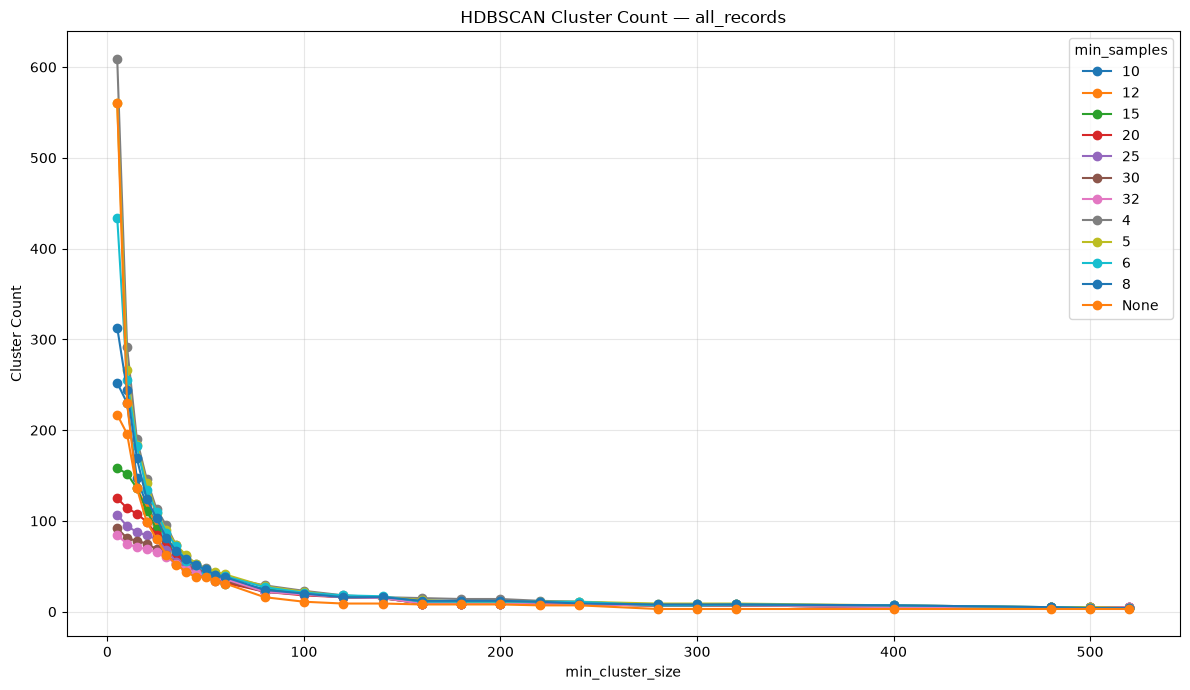

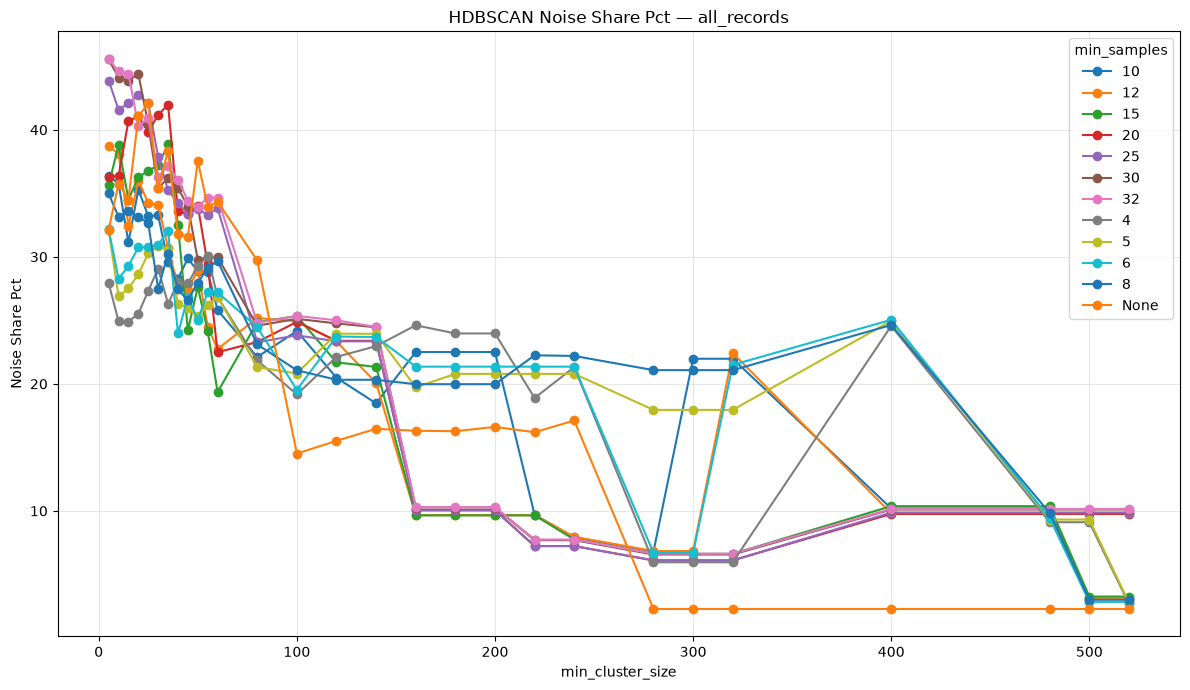

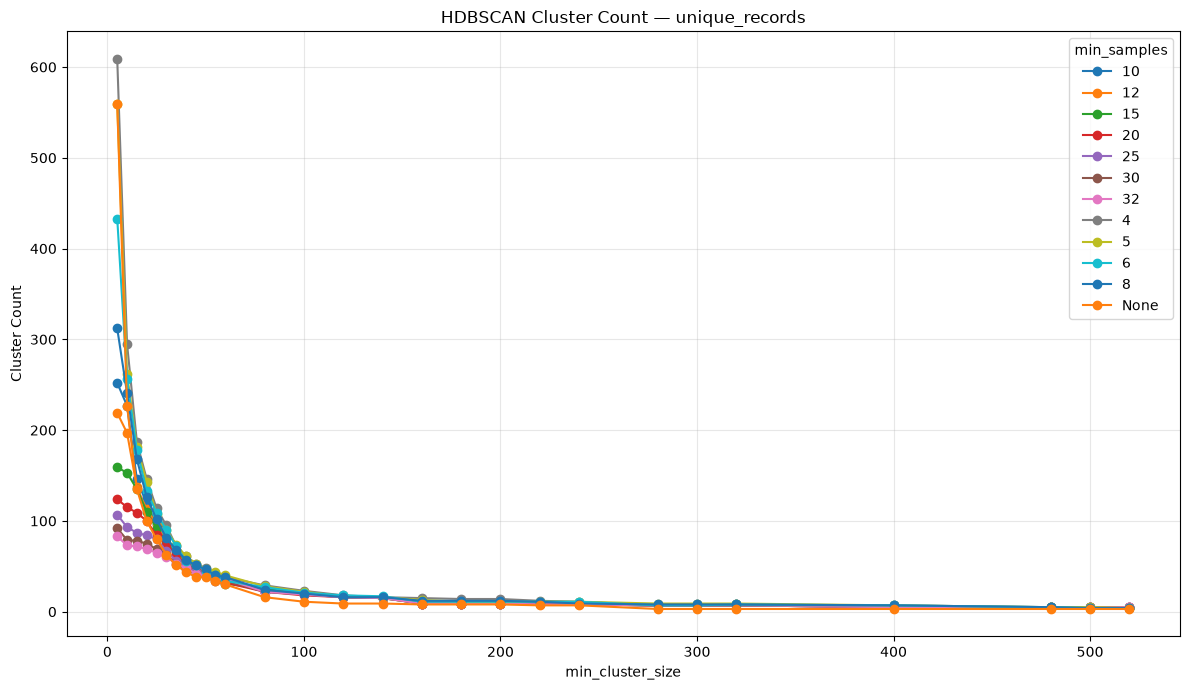

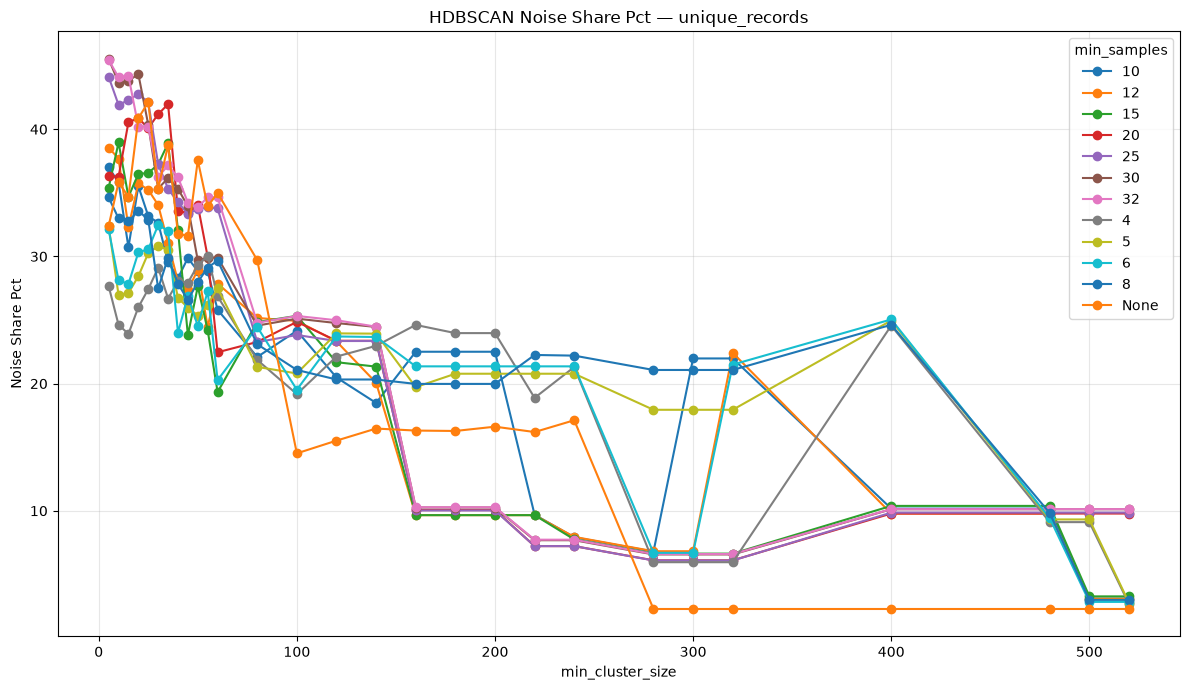

In [18]:
# %% HDBSCAN plots
# Defensive pivot_table aggregation prevents the original duplicate-index
# ValueError. Since candidate values are now deduplicated, aggregation should
# normally not be needed, but it is safer for future edits.
for dataset_name, results in hdbscan_parameter_results.items():
    plot_results = results.copy()
    plot_results["min_samples_plot"] = plot_results["min_samples"].map(
        lambda value: "None" if pd.isna(value) else str(int(value))
    )
    for metric in ["cluster_count", "noise_share_pct"]:
        pivot = plot_results.pivot_table(
            index="min_cluster_size", columns="min_samples_plot",
            values=metric, aggfunc="mean"
        )
        ax = pivot.plot(kind="line", marker="o", figsize=(12, 7))
        ax.set_xlabel("min_cluster_size")
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.set_title(f"HDBSCAN {metric.replace('_', ' ').title()} — {dataset_name}")
        ax.grid(alpha=0.3)
        ax.legend(title="min_samples")
        plt.tight_layout()
        plt.show()


## Combined screening

Both grids go into one table (1,200 runs: 264 DBSCAN and 336 HDBSCAN per dataset) and are screened again. 521 runs pass for all records and 519 for unique records, ranging from almost no noise with one cluster of 64.41% of records to over 45% noise with many small clusters. The screen removes the extremes but does not choose a setting.

In [19]:

# %% Combine DBSCAN and HDBSCAN parameter experiment tables

comparison_frames = []

# DBSCAN parameter experiments
for dataset_name, results in dbscan_results.items():

    frame = results.copy()

    # Add the algorithm name explicitly.
    frame["algorithm"] = "DBSCAN"

    # DBSCAN does not use min_cluster_size.
    frame["min_cluster_size"] = np.nan

    # Keep the dataset identifier consistent.
    frame["dataset"] = dataset_name

    comparison_frames.append(frame)


# HDBSCAN parameter experiments
for dataset_name, results in hdbscan_parameter_results.items():

    frame = results.copy()

    # Add the algorithm name explicitly.
    frame["algorithm"] = "HDBSCAN"

    # HDBSCAN does not use eps_km.
    frame["eps_km"] = np.nan

    # Keep the dataset identifier consistent.
    frame["dataset"] = dataset_name

    comparison_frames.append(frame)


# Combine both algorithms without dropping any experiment rows.
algorithm_comparison = pd.concat(
    comparison_frames,
    ignore_index=True,
    sort=False
)

# Standardize the column order for easier comparison.
comparison_columns = [
    "dataset",
    "algorithm",
    "eps_km",
    "min_cluster_size",
    "min_samples",
    "cluster_count",
    "clustered_records",
    "clustered_share_pct",
    "noise_records",
    "noise_share_pct",
    "largest_cluster_size",
    "largest_cluster_share_pct",
    "smallest_cluster_size",
    "median_cluster_size"
]

algorithm_comparison = algorithm_comparison[
    comparison_columns
]


# %% Classify experiment results

def classify_clustering_result(row):

    warnings = []

    if row["cluster_count"] < 2:
        warnings.append("fewer_than_two_clusters")

    if row["noise_share_pct"] >= 80:
        warnings.append("very_high_noise")

    if row["largest_cluster_share_pct"] >= 80:
        warnings.append("dominant_cluster")

    if row["cluster_count"] >= 100:
        warnings.append("many_clusters")

    if pd.isna(row["median_cluster_size"]):
        warnings.append("no_detected_clusters")

    return (
        "; ".join(warnings)
        if warnings
        else "review_candidate"
    )


algorithm_comparison["diagnostic"] = (
    algorithm_comparison.apply(
        classify_clustering_result,
        axis=1
    )
)


# %% Validate the combined experiment table

print("Total experiment rows:", len(algorithm_comparison))

print("\nRows by algorithm and dataset:")

display(
    algorithm_comparison
    .groupby(["dataset", "algorithm"])
    .size()
    .rename("experiment_count")
    .reset_index()
)


# %% Screen candidate configurations

for dataset_name in clustering_datasets:

    print(
        f"\n{'=' * 70}\n"
        f"EXPERIMENT SCREENING — {dataset_name}\n"
        f"{'=' * 70}"
    )

    candidates = algorithm_comparison[
        (algorithm_comparison["dataset"] == dataset_name)
        & (
            algorithm_comparison["diagnostic"]
            == "review_candidate"
        )
    ].copy()

    display(
        candidates[
            [
                "algorithm",
                "eps_km",
                "min_cluster_size",
                "min_samples",
                "cluster_count",
                "clustered_share_pct",
                "noise_share_pct",
                "largest_cluster_share_pct",
                "median_cluster_size"
            ]
        ]
        .sort_values(
            ["algorithm", "noise_share_pct", "cluster_count"]
        )
        .reset_index(drop=True)
        .round(2)
    )


Total experiment rows: 1200

Rows by algorithm and dataset:


,dataset,algorithm,experiment_count
0,all_records,DBSCAN,264
1,all_records,HDBSCAN,336
2,unique_records,DBSCAN,264
3,unique_records,HDBSCAN,336



EXPERIMENT SCREENING — all_records


,algorithm,eps_km,min_cluster_size,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size
0,DBSCAN,520.0,NaN,4.0,14,99.87,0.13,64.41,51.0
1,DBSCAN,480.0,NaN,4.0,15,99.84,0.16,64.41,54.0
2,DBSCAN,500.0,NaN,4.0,15,99.84,0.16,64.41,54.0
3,DBSCAN,400.0,NaN,4.0,16,99.84,0.16,64.41,57.5
4,DBSCAN,520.0,NaN,5.0,13,99.83,0.17,64.41,54.0
...,...,...,...,...,...,...,...,...,...
516,HDBSCAN,NaN,20.0,30.0,75,55.61,44.39,2.76,54.0
517,HDBSCAN,NaN,15.0,32.0,71,55.58,44.42,2.75,62.0
518,HDBSCAN,NaN,10.0,32.0,75,55.40,44.60,2.75,57.0
519,HDBSCAN,NaN,5.0,30.0,92,54.46,45.54,2.76,46.0



EXPERIMENT SCREENING — unique_records


,algorithm,eps_km,min_cluster_size,min_samples,cluster_count,clustered_share_pct,noise_share_pct,largest_cluster_share_pct,median_cluster_size
0,DBSCAN,520.0,NaN,4.0,14,99.87,0.13,64.41,51.0
1,DBSCAN,480.0,NaN,4.0,15,99.84,0.16,64.41,54.0
2,DBSCAN,500.0,NaN,4.0,15,99.84,0.16,64.41,54.0
3,DBSCAN,400.0,NaN,4.0,16,99.84,0.16,64.41,57.5
4,DBSCAN,520.0,NaN,5.0,13,99.83,0.17,64.41,54.0
...,...,...,...,...,...,...,...,...,...
514,HDBSCAN,NaN,10.0,32.0,73,55.92,44.08,2.75,61.0
515,HDBSCAN,NaN,15.0,32.0,72,55.80,44.20,2.75,61.5
516,HDBSCAN,NaN,20.0,30.0,75,55.67,44.33,2.76,54.0
517,HDBSCAN,NaN,5.0,32.0,83,54.54,45.46,2.75,53.0


In [20]:
# Shows unique_records only: `candidates` keeps the last dataset of the loop above.
# The save cell rebuilds the list for both datasets.
candidates

,dataset,algorithm,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size,diagnostic
270,unique_records,DBSCAN,25.0,NaN,15.0,98,5668,59.744914,3819,40.255086,479,5.049014,6,29.0,review_candidate
271,unique_records,DBSCAN,25.0,NaN,20.0,72,4735,49.910404,4752,50.089596,464,4.890903,15,41.0,review_candidate
272,unique_records,DBSCAN,25.0,NaN,25.0,53,4041,42.595130,5446,57.404870,429,4.521977,25,44.0,review_candidate
273,unique_records,DBSCAN,25.0,NaN,30.0,41,3423,36.080953,6064,63.919047,404,4.258459,31,49.0,review_candidate
274,unique_records,DBSCAN,25.0,NaN,32.0,39,3267,34.436597,6220,65.563403,395,4.163592,33,50.0,review_candidate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,unique_records,HDBSCAN,NaN,520.0,15.0,4,9177,96.732371,310,3.267629,3607,38.020449,860,2355.0,review_candidate
1196,unique_records,HDBSCAN,NaN,520.0,20.0,5,8559,90.218193,928,9.781807,3620,38.157479,860,900.0,review_candidate
1197,unique_records,HDBSCAN,NaN,520.0,25.0,5,8552,90.144408,935,9.855592,3623,38.189101,858,901.0,review_candidate
1198,unique_records,HDBSCAN,NaN,520.0,30.0,5,8527,89.880890,960,10.119110,3614,38.094234,844,900.0,review_candidate


In [21]:
algorithm_comparison

,dataset,algorithm,eps_km,min_cluster_size,min_samples,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size,diagnostic
0,all_records,DBSCAN,25.0,NaN,4.0,289,7986,84.169477,1502,15.830523,948,9.991568,3,7.0,many_clusters
1,all_records,DBSCAN,25.0,NaN,5.0,221,7639,80.512226,1849,19.487774,930,9.801855,3,11.0,many_clusters
2,all_records,DBSCAN,25.0,NaN,6.0,195,7391,77.898398,2097,22.101602,890,9.380270,3,13.0,many_clusters
3,all_records,DBSCAN,25.0,NaN,8.0,160,6975,73.513912,2513,26.486088,869,9.158938,4,17.0,many_clusters
4,all_records,DBSCAN,25.0,NaN,10.0,133,6592,69.477234,2896,30.522766,843,8.884907,10,20.0,many_clusters
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1195,unique_records,HDBSCAN,NaN,520.0,15.0,4,9177,96.732371,310,3.267629,3607,38.020449,860,2355.0,review_candidate
1196,unique_records,HDBSCAN,NaN,520.0,20.0,5,8559,90.218193,928,9.781807,3620,38.157479,860,900.0,review_candidate
1197,unique_records,HDBSCAN,NaN,520.0,25.0,5,8552,90.144408,935,9.855592,3623,38.189101,858,901.0,review_candidate
1198,unique_records,HDBSCAN,NaN,520.0,30.0,5,8527,89.880890,960,10.119110,3614,38.094234,844,900.0,review_candidate


## Candidate models

Two DBSCAN and three HDBSCAN settings, picked by hand from the tables and plots above; the notebook does not record why. Each is fitted on both datasets and its record-level labels are kept.

In [22]:

# %% Final candidate model comparison: DBSCAN vs HDBSCAN

# import numpy as np
# import pandas as pd

# from sklearn.cluster import DBSCAN
# from hdbscan import HDBSCAN

earth_radius_km = 6371.0088

# Keep the candidate parameter combinations in one place.
# Picked by hand from the screening tables and plots above.
dbscan_candidates = [
    {"candidate": "DBSCAN_A", "eps_km": 40, "min_samples": 15},
    {"candidate": "DBSCAN_B", "eps_km": 45, "min_samples": 15},
]

hdbscan_candidates = [
    {
        "candidate": "HDBSCAN_A",
        "min_cluster_size": 15,
        "min_samples": 4,
    },
    {
        "candidate": "HDBSCAN_B",
        "min_cluster_size": 20,
        "min_samples": 4,
    },
    {
        "candidate": "HDBSCAN_C",
        "min_cluster_size": 15,
        "min_samples": 10,
    },
]

# Store both the summary metrics and each model's record-level labels.
final_model_summaries = []
final_model_results = {}

for dataset_name, df in clustering_datasets.items():

    # Haversine distance requires latitude and longitude in radians.
    coordinates_rad = df[
        ["latitude_rad", "longitude_rad"]
    ].to_numpy()

    total_records = len(df)

    # -------------------------
    # DBSCAN candidates
    # -------------------------
    for params in dbscan_candidates:

        eps_rad = params["eps_km"] / earth_radius_km

        model = DBSCAN(
            eps=eps_rad,
            min_samples=params["min_samples"],
            metric="haversine",
        )

        labels = model.fit_predict(coordinates_rad)

        algorithm = "DBSCAN"
        candidate = params["candidate"]

        # Save labels alongside the original records.
        result_key = (dataset_name, algorithm, candidate)
        labeled_df = df.copy()
        labeled_df["cluster"] = labels
        final_model_results[result_key] = labeled_df

        # Calculate comparison metrics.
        noise_mask = labels == -1
        noise_records = int(noise_mask.sum())
        clustered_records = total_records - noise_records

        cluster_sizes = (
            pd.Series(labels[~noise_mask])
            .value_counts()
        )

        cluster_count = len(cluster_sizes)
        largest_size = (
            int(cluster_sizes.max()) if cluster_count else 0
        )
        smallest_size = (
            int(cluster_sizes.min()) if cluster_count else 0
        )
        median_size = (
            float(cluster_sizes.median())
            if cluster_count else np.nan
        )

        final_model_summaries.append({
            "dataset": dataset_name,
            "algorithm": algorithm,
            "candidate": candidate,
            "eps_km": params["eps_km"],
            "min_cluster_size": np.nan,
            "min_samples": params["min_samples"],
            "total_records": total_records,
            "cluster_count": cluster_count,
            "clustered_records": clustered_records,
            "clustered_share_pct": (
                clustered_records / total_records * 100
                if total_records else np.nan
            ),
            "noise_records": noise_records,
            "noise_share_pct": (
                noise_records / total_records * 100
                if total_records else np.nan
            ),
            "largest_cluster_size": largest_size,
            "largest_cluster_share_pct": (
                largest_size / total_records * 100
                if total_records else np.nan
            ),
            "smallest_cluster_size": smallest_size,
            "median_cluster_size": median_size,
        })

    # -------------------------
    # HDBSCAN candidates
    # -------------------------
    for params in hdbscan_candidates:

        # algorithm and copy are left at their defaults here, hence the FutureWarning in the output.
        model = HDBSCAN(
            min_cluster_size=params["min_cluster_size"],
            min_samples=params["min_samples"],
            metric="haversine",
        )

        labels = model.fit_predict(coordinates_rad)

        algorithm = "HDBSCAN"
        candidate = params["candidate"]

        result_key = (dataset_name, algorithm, candidate)
        labeled_df = df.copy()
        labeled_df["cluster"] = labels
        final_model_results[result_key] = labeled_df

        noise_mask = labels == -1
        noise_records = int(noise_mask.sum())
        clustered_records = total_records - noise_records

        cluster_sizes = (
            pd.Series(labels[~noise_mask])
            .value_counts()
        )

        cluster_count = len(cluster_sizes)
        largest_size = (
            int(cluster_sizes.max()) if cluster_count else 0
        )
        smallest_size = (
            int(cluster_sizes.min()) if cluster_count else 0
        )
        median_size = (
            float(cluster_sizes.median())
            if cluster_count else np.nan
        )

        final_model_summaries.append({
            "dataset": dataset_name,
            "algorithm": algorithm,
            "candidate": candidate,
            "eps_km": np.nan,  # HDBSCAN has no eps_km parameter here
            "min_cluster_size": params["min_cluster_size"],
            "min_samples": params["min_samples"],
            "total_records": total_records,
            "cluster_count": cluster_count,
            "clustered_records": clustered_records,
            "clustered_share_pct": (
                clustered_records / total_records * 100
                if total_records else np.nan
            ),
            "noise_records": noise_records,
            "noise_share_pct": (
                noise_records / total_records * 100
                if total_records else np.nan
            ),
            "largest_cluster_size": largest_size,
            "largest_cluster_share_pct": (
                largest_size / total_records * 100
                if total_records else np.nan
            ),
            "smallest_cluster_size": smallest_size,
            "median_cluster_size": median_size,
        })

# One comparison table for all datasets and candidate models.
final_model_comparison = pd.DataFrame(final_model_summaries)

final_model_comparison = final_model_comparison.sort_values(
    ["dataset", "algorithm", "candidate"]
).reset_index(drop=True)

final_model_comparison.round(2)


D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\venv\Lib\site-packages\sklearn\clu

,dataset,algorithm,candidate,eps_km,min_cluster_size,min_samples,total_records,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,all_records,DBSCAN,DBSCAN_A,40.0,NaN,15,9488,84,7022,74.01,2466,25.99,1027,10.82,15,31.5
1,all_records,DBSCAN,DBSCAN_B,45.0,NaN,15,9488,83,7310,77.04,2178,22.96,1796,18.93,13,31.0
2,all_records,HDBSCAN,HDBSCAN_A,NaN,15.0,4,9488,190,7126,75.11,2362,24.89,168,1.77,15,29.0
3,all_records,HDBSCAN,HDBSCAN_B,NaN,20.0,4,9488,146,7066,74.47,2422,25.53,253,2.67,20,36.5
4,all_records,HDBSCAN,HDBSCAN_C,NaN,15.0,10,9488,147,6534,68.87,2954,31.13,889,9.37,15,31.0
5,unique_records,DBSCAN,DBSCAN_A,40.0,NaN,15,9487,84,7021,74.01,2466,25.99,1026,10.81,15,31.5
6,unique_records,DBSCAN,DBSCAN_B,45.0,NaN,15,9487,83,7309,77.04,2178,22.96,1795,18.92,13,31.0
7,unique_records,HDBSCAN,HDBSCAN_A,NaN,15.0,4,9487,187,7219,76.09,2268,23.91,253,2.67,15,29.0
8,unique_records,HDBSCAN,HDBSCAN_B,NaN,20.0,4,9487,146,7020,74.00,2467,26.00,253,2.67,20,36.5
9,unique_records,HDBSCAN,HDBSCAN_C,NaN,15.0,10,9487,146,6573,69.28,2914,30.72,887,9.35,15,31.5


Results for all records (the unique-records rows are close):

| Candidate | Setting | Clusters | Noise | Largest cluster |
|---|---|---|---|---|
| DBSCAN_A | eps 40 km, min_samples 15 | 84 | 25.99% | 1,027 (10.82%) |
| DBSCAN_B | eps 45 km, min_samples 15 | 83 | 22.96% | 1,796 (18.93%) |
| HDBSCAN_A | min_cluster_size 15, min_samples 4 | 190 | 24.89% | 168 (1.77%) |
| HDBSCAN_B | min_cluster_size 20, min_samples 4 | 146 | 25.53% | 253 (2.67%) |
| HDBSCAN_C | min_cluster_size 15, min_samples 10 | 147 | 31.13% | 889 (9.37%) |

Going from 40 to 45 km lowers DBSCAN's noise but grows its largest cluster from 1,027 to 1,796 records, as neighbouring hubs merge. HDBSCAN_A and HDBSCAN_B keep every cluster small at a similar noise level. HDBSCAN is also more sensitive to small changes in the data: dropping the one duplicate record moves HDBSCAN_A from 190 to 187 clusters and its largest cluster from 168 to 253 records, while DBSCAN's largest cluster loses one record.

## Selected models

We kept DBSCAN_B (45 km, `min_samples` 15) and HDBSCAN_A (`min_cluster_size` 15, `min_samples` 4) for both datasets. `None` is both a valid HDBSCAN value and the "not chosen yet" placeholder in this dictionary, hence the separate flag. The refit below reproduces the candidate results exactly: 83 DBSCAN clusters with 22.96% noise, and 190 and 187 HDBSCAN clusters.

In [23]:
# %% Select final model parameters
# IMPORTANT: Replace None only after reviewing the experiment tables and plots.
# HDBSCAN allows min_samples=None; in this selection dictionary, None is also
# used as an unselected placeholder. To select HDBSCAN's valid None setting,
# use the separate boolean 'hdbscan_selected' below, or set it to True.
# DBSCAN_B and HDBSCAN_A from the candidate comparison above.
selected_parameters = {
    "all_records": {
        "DBSCAN": {"eps_km": 45, "min_samples": 15},
        "HDBSCAN": {"min_cluster_size": 15, "min_samples": 4},
    },
    "unique_records": {
        "DBSCAN": {"eps_km": 45, "min_samples": 15},
        "HDBSCAN": {"min_cluster_size": 15, "min_samples": 4},
    },
}

# Set a dataset's flag to True only when you deliberately choose HDBSCAN
# min_samples=None. Otherwise, leave it False until parameters are selected.
hdbscan_selected_min_samples_is_none = {
    "all_records": False,
    "unique_records": False,
}


In [24]:
# %% Inspect selected parameters

print("Selected parameters:")

for dataset_name, algorithms in selected_parameters.items():
    print(f"\n{dataset_name}")

    for algorithm, params in algorithms.items():
        print(f"  {algorithm}: {params}")

print("\nHDBSCAN None-selection flags:")

print(hdbscan_selected_min_samples_is_none)

Selected parameters:

all_records
  DBSCAN: {'eps_km': 45, 'min_samples': 15}
  HDBSCAN: {'min_cluster_size': 15, 'min_samples': 4}

unique_records
  DBSCAN: {'eps_km': 45, 'min_samples': 15}
  HDBSCAN: {'min_cluster_size': 15, 'min_samples': 4}

HDBSCAN None-selection flags:
{'all_records': False, 'unique_records': False}


In [25]:
# %% Fit selected models
algorithm_spatial_results = {"DBSCAN": {}, "HDBSCAN": {}}
for dataset_name, df in clustering_datasets.items():
    coordinates_rad = df[["latitude_rad", "longitude_rad"]].to_numpy()

    dbscan_params = selected_parameters[dataset_name]["DBSCAN"]
    if dbscan_params["eps_km"] is not None and dbscan_params["min_samples"] is not None:
        dbscan_model = DBSCAN(
            eps=float(dbscan_params["eps_km"]) / EARTH_RADIUS_KM,
            min_samples=int(dbscan_params["min_samples"]),
            metric="haversine",
        )
        result = df.copy()
        result["cluster"] = dbscan_model.fit_predict(coordinates_rad)
        algorithm_spatial_results["DBSCAN"][dataset_name] = result

    hdbscan_params = selected_parameters[dataset_name]["HDBSCAN"]
    mcs = hdbscan_params["min_cluster_size"]
    ms = hdbscan_params["min_samples"]
    hdbscan_has_selection = (
        mcs is not None
        and (ms is not None or hdbscan_selected_min_samples_is_none[dataset_name])
    )
    if hdbscan_has_selection:
        selected_ms = None if hdbscan_selected_min_samples_is_none[dataset_name] else int(ms)
        hdbscan_model = HDBSCAN(
            min_cluster_size=int(mcs),
            min_samples=selected_ms,
            metric="haversine",
            algorithm="auto",
            copy=True,
        )
        result = df.copy()
        result["cluster"] = hdbscan_model.fit_predict(coordinates_rad)
        algorithm_spatial_results["HDBSCAN"][dataset_name] = result

print("Selected models fitted where valid parameters were provided.")
for algorithm, datasets in algorithm_spatial_results.items():
    print(f"{algorithm}: {list(datasets.keys())}")


Selected models fitted where valid parameters were provided.
DBSCAN: ['all_records', 'unique_records']
HDBSCAN: ['all_records', 'unique_records']


In [26]:
# %% Final algorithm summary
# This will contain zero rows until at least one model is selected and fitted.
final_algorithm_summary_rows = []
for algorithm, datasets in algorithm_spatial_results.items():
    for dataset_name, result in datasets.items():
        total_records = len(result)
        noise_mask = result["cluster"] == -1
        noise_records = int(noise_mask.sum())
        clustered = result.loc[~noise_mask]
        cluster_sizes = clustered["cluster"].value_counts()
        final_algorithm_summary_rows.append({
            "dataset": dataset_name,
            "algorithm": algorithm,
            "total_records": total_records,
            "cluster_count": int(cluster_sizes.size),
            "clustered_records": len(clustered),
            "clustered_share_pct": len(clustered) / total_records * 100 if total_records else np.nan,
            "noise_records": noise_records,
            "noise_share_pct": noise_records / total_records * 100 if total_records else np.nan,
            "largest_cluster_size": int(cluster_sizes.max()) if not cluster_sizes.empty else 0,
            "largest_cluster_share_pct": float(cluster_sizes.max() / total_records * 100) if not cluster_sizes.empty and total_records else 0,
            "smallest_cluster_size": int(cluster_sizes.min()) if not cluster_sizes.empty else 0,
            "median_cluster_size": float(cluster_sizes.median()) if not cluster_sizes.empty else np.nan,
        })

final_algorithm_summary = pd.DataFrame(final_algorithm_summary_rows)
if final_algorithm_summary.empty:
    print(
        "No final models have been fitted yet. Choose parameters in "
        "selected_parameters, then rerun the final-model cells."
    )
else:
    display(final_algorithm_summary.round(2))


,dataset,algorithm,total_records,cluster_count,clustered_records,clustered_share_pct,noise_records,noise_share_pct,largest_cluster_size,largest_cluster_share_pct,smallest_cluster_size,median_cluster_size
0,all_records,DBSCAN,9488,83,7310,77.04,2178,22.96,1796,18.93,13,31.0
1,unique_records,DBSCAN,9487,83,7309,77.04,2178,22.96,1795,18.92,13,31.0
2,all_records,HDBSCAN,9488,190,7126,75.11,2362,24.89,168,1.77,15,29.0
3,unique_records,HDBSCAN,9487,187,7219,76.09,2268,23.91,253,2.67,15,29.0


## Maps of the selected models

Longitude against latitude in plain degrees, without a map projection; gray is noise. The legend is hidden when a model has many clusters. The isolated gray points off East Africa and near Antarctica are swapped records. The large blue DBSCAN cluster in western Europe chains Belgian and German breweries into one.

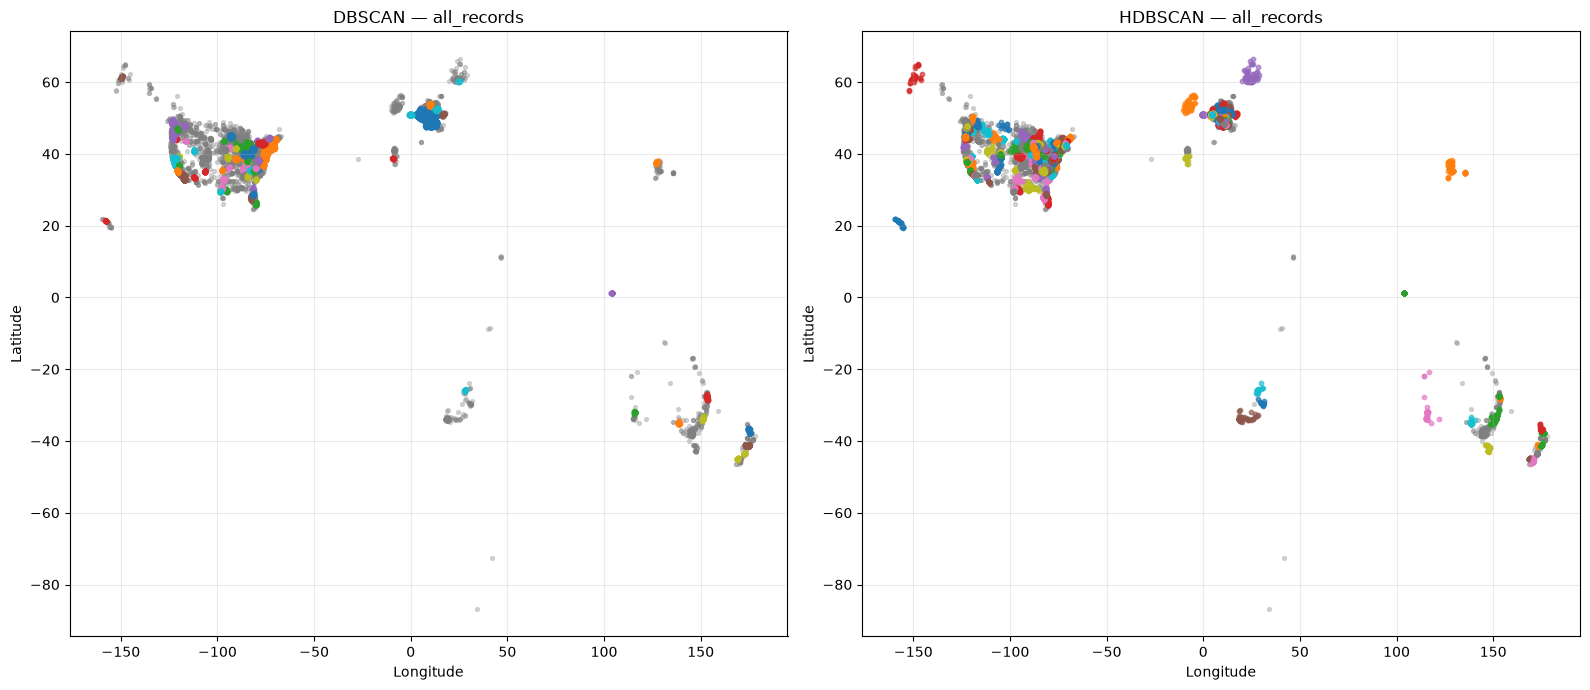

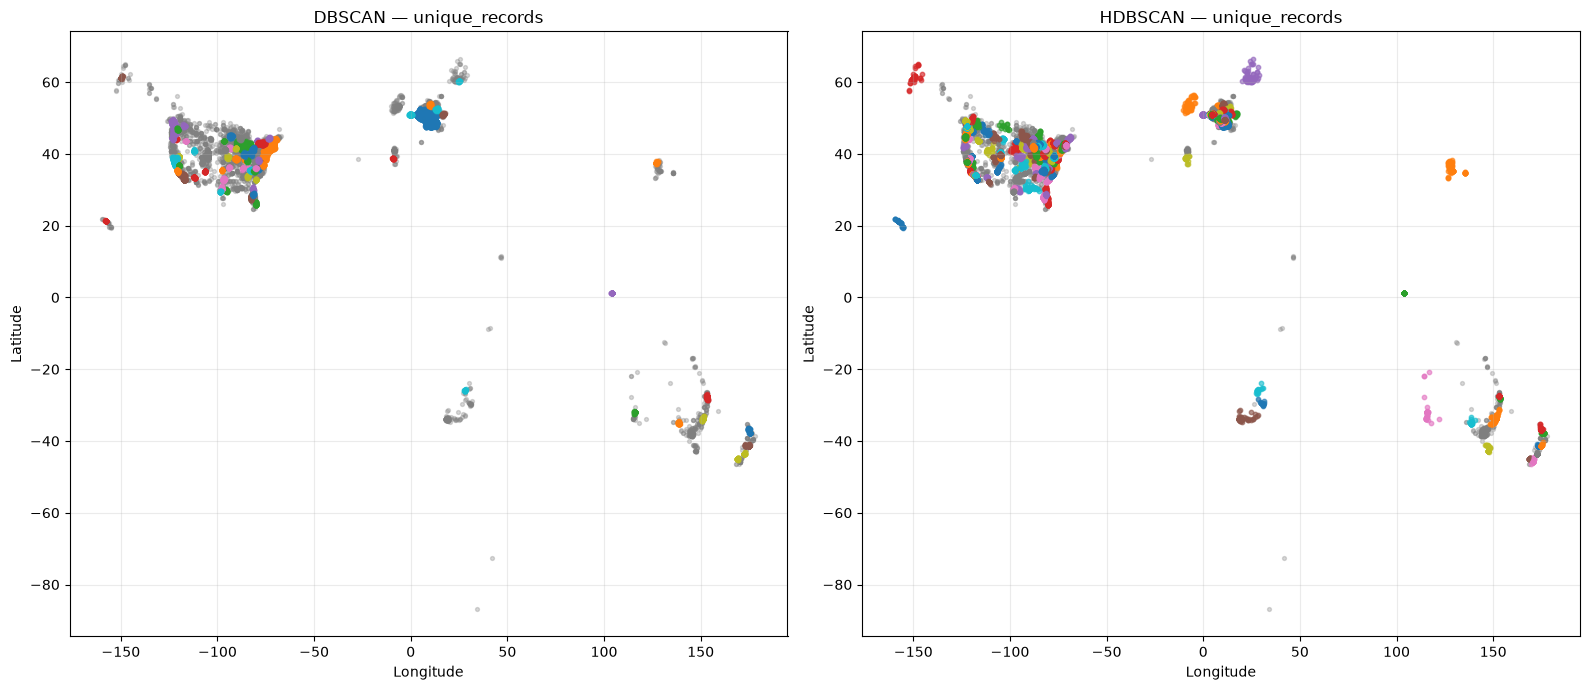

In [27]:
# %% Compare final spatial patterns
# Avoid the 'number of columns must be a positive integer, not 0' error when
# no model is selected for a dataset.
for dataset_name in clustering_datasets:
    available_algorithms = [
        algorithm for algorithm, datasets in algorithm_spatial_results.items()
        if dataset_name in datasets
    ]
    if not available_algorithms:
        print(
            f"Skipping spatial plot for {dataset_name}: no selected model "
            "has been fitted yet."
        )
        continue

    # Plain degrees on both axes, no map projection.
    fig, axes = plt.subplots(
        1, len(available_algorithms),
        figsize=(8 * len(available_algorithms), 7),
        squeeze=False,
    )
    for ax, algorithm in zip(axes[0], available_algorithms):
        plot_df = algorithm_spatial_results[algorithm][dataset_name]
        noise = plot_df[plot_df["cluster"] == -1]
        clustered = plot_df[plot_df["cluster"] != -1]
        ax.scatter(noise["longitude"], noise["latitude"], s=8, alpha=0.3, color="gray", label="Noise")
        for cluster_label, subset in clustered.groupby("cluster"):
            ax.scatter(subset["longitude"], subset["latitude"], s=10, alpha=0.65, label=f"Cluster {cluster_label}")
        ax.set_title(f"{algorithm} — {dataset_name}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.25)
        if 0 < clustered["cluster"].nunique() <= 15:
            ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    fig.tight_layout()
    plt.show()



In [28]:
for algorithm, datasets in algorithm_spatial_results.items():
    print(f"\n{algorithm}")
    print("Available datasets:", list(datasets.keys()))


DBSCAN
Available datasets: ['all_records', 'unique_records']

HDBSCAN
Available datasets: ['all_records', 'unique_records']


## Cluster and noise summaries

For each selected model: cluster sizes, each cluster's bounding box, mean center and farthest member, noise counts by state, and the noise records themselves. Distances use the stored, uncorrected coordinates.

In [29]:
# %% Optional: cluster-size and geographic summaries for fitted models
cluster_size_summary = {}
cluster_geography_summary = {}
noise_by_region = {}
noise_record_details = {}

for algorithm, datasets in algorithm_spatial_results.items():
    for dataset_name, df in datasets.items():
        total_records = len(df)
        clustered = df[df["cluster"] != -1].copy()
        noise_df = df[df["cluster"] == -1].copy()

        sizes = clustered["cluster"].value_counts().rename_axis("cluster").reset_index(name="cluster_size")
        if not sizes.empty:
            sizes["cluster_share_pct"] = sizes["cluster_size"] / total_records * 100
            sizes["share_of_clustered_records_pct"] = sizes["cluster_size"] / len(clustered) * 100 if len(clustered) else np.nan
            sizes = sizes.sort_values("cluster_size", ascending=False).reset_index(drop=True)
            sizes.insert(0, "rank", np.arange(1, len(sizes) + 1))
        cluster_size_summary[(algorithm, dataset_name)] = sizes

        if clustered.empty:
            cluster_geography_summary[(algorithm, dataset_name)] = pd.DataFrame()
        else:
            geo = clustered.groupby("cluster").agg(
                cluster_size=("cluster", "size"),
                center_latitude=("latitude", "mean"),
                center_longitude=("longitude", "mean"),
                min_latitude=("latitude", "min"),
                max_latitude=("latitude", "max"),
                min_longitude=("longitude", "min"),
                max_longitude=("longitude", "max"),
            ).reset_index()
            geo["cluster_share_pct"] = geo["cluster_size"] / total_records * 100 if total_records else np.nan
            clustered = clustered.merge(geo[["cluster", "center_latitude", "center_longitude"]], on="cluster", how="left")
            # Distance from each record to its cluster's mean center, on the uncorrected coordinates.
            clustered["distance_from_cluster_center_km"] = haversine_km(
                clustered["latitude"], clustered["longitude"],
                clustered["center_latitude"], clustered["center_longitude"],
            )
            max_distance = clustered.groupby("cluster")["distance_from_cluster_center_km"].max().rename(
                "max_distance_from_cluster_center_km"
            ).reset_index()
            geo = geo.merge(max_distance, on="cluster", how="left")
            cluster_geography_summary[(algorithm, dataset_name)] = geo.sort_values(
                "cluster_size", ascending=False
            ).reset_index(drop=True)

        if {"country", "state_province"}.issubset(noise_df.columns):
            noise_by_region[(algorithm, dataset_name)] = (
                noise_df.groupby(["country", "state_province"], dropna=False)
                .size().reset_index(name="noise_records")
                .sort_values("noise_records", ascending=False)
            )
        noise_columns = [c for c in ["name", "city", "state_province", "country", "latitude", "longitude"] if c in noise_df.columns]
        noise_record_details[(algorithm, dataset_name)] = noise_df[noise_columns].copy()

print("Optional cluster-size, geography, and noise summaries created for fitted models.")


Optional cluster-size, geography, and noise summaries created for fitted models.


In [30]:
display(cluster_size_summary[("DBSCAN", "all_records")].head(20))


,rank,cluster,cluster_size,cluster_share_pct,share_of_clustered_records_pct
0,1,0,1796,18.929174,24.569083
1,2,11,906,9.548904,12.393981
2,3,5,457,4.816610,6.251710
3,4,2,434,4.574199,5.937073
4,5,14,389,4.099916,5.321477
5,6,9,321,3.383221,4.391245
6,7,4,225,2.371417,3.077975
7,8,7,215,2.266020,2.941176
8,9,27,117,1.233137,1.600547
9,10,10,87,0.916948,1.190150


In [31]:
print(cluster_geography_summary.keys())

dict_keys([('DBSCAN', 'all_records'), ('DBSCAN', 'unique_records'), ('HDBSCAN', 'all_records'), ('HDBSCAN', 'unique_records')])


In [32]:
display(cluster_geography_summary[("HDBSCAN", "all_records")].head(20))


,cluster,cluster_size,center_latitude,center_longitude,min_latitude,max_latitude,min_longitude,max_longitude,cluster_share_pct,max_distance_from_cluster_center_km
0,80,168,45.527546,-122.689835,45.210657,46.287285,-123.191781,-122.270205,1.770658,86.013607
1,27,155,-37.781178,145.083367,-38.518592,-36.091146,143.564484,147.371597,1.633642,248.356544
2,161,138,49.886692,11.038918,49.512065,50.258959,10.586870,11.542900,1.454469,45.111187
3,124,123,44.890301,-92.969807,43.739974,46.519948,-94.428880,-90.851155,1.296374,208.156265
4,110,118,51.267502,7.254873,50.543177,52.201244,5.983200,8.795298,1.243676,137.968382
5,171,115,41.862341,-87.827999,41.417636,42.382643,-88.338381,-87.268878,1.212057,64.495329
6,185,113,41.915488,-72.733397,41.077057,42.934270,-73.519558,-72.189731,1.190978,119.285775
7,32,112,-33.792034,150.965138,-35.323520,-31.087836,148.215290,152.882823,1.180438,347.976543
8,168,107,50.865448,4.245193,50.669631,51.055268,3.811901,4.418427,1.127740,30.410853
9,72,97,39.734264,-104.978219,39.532374,39.928562,-105.091638,-104.760170,1.022344,24.186659


DBSCAN's largest cluster holds 1,796 records, about a quarter of all clustered records; the next has 906. HDBSCAN's largest clusters are single metro areas or regions: Portland, Oregon (168 records, farthest member 86 km from the center), Melbourne, Franconia, Minneapolis–St Paul, Rhine–Ruhr, Chicago, Sydney, Brussels and Denver. A few cover much more, such as one spanning South Korea that reaches western Japan (farthest member 639.8 km from the center). The next table counts DBSCAN noise by state; California, Michigan and Oregon have the most.

In [33]:
display(noise_by_region[("DBSCAN", "unique_records")].head(20))


,country,state_province,noise_records
120,United States,California,76
136,United States,Michigan,65
151,United States,Oregon,65
1,Australia,NSW,64
121,United States,Colorado,59
160,United States,Washington,57
140,United States,Montana,56
147,United States,North Carolina,56
129,United States,Iowa,54
162,United States,Wisconsin,50


In [34]:
display(noise_record_details[("DBSCAN", "all_records")].head(20))


,name,city,state_province,country,latitude,longitude
15,1000 Hills Brewing Company,Durban,KwaZulu-Natal,South Africa,-29.771100,30.706300
21,1188 Brewing Co,John Day,Oregon,United States,44.414656,-118.921875
22,12 Acres Brewing Company,Killeshin,Laois,Ireland,52.849308,-6.979344
37,1718 Ocracoke Brewing,Ocracoke,North Carolina,United States,35.107154,-75.971761
39,1812 Brewery,Cumberland,Maryland,United States,39.702148,-78.700853
40,1817 Brewery,okolona,Mississippi,United States,34.001703,-88.750264
42,1850 Brewing Company,Mariposa,California,United States,37.570148,-119.903659
45,1905 Brewing Company,Assumption,Illinois,United States,39.517256,-89.050364
46,1912 Brewing,Tucson,Arizona,United States,32.246737,-110.992750
48,2 Basset Brewery,White Sulphur Springs,Montana,United States,46.548076,-110.900486


# Saving results

**Historical: do not run the next cell against the project database.**

The cell collects 44 tables: the two parameter grids, the k-distances, the combined comparison, the candidate and selected labels, the cluster and noise summaries, the review candidates and the parameter settings. Then it:

1. drops **every** existing table in `data/clustering_results.db`, not only its own. Today that would remove the `allruns_*` tables of `brewery_clustering_all_runs.ipynb`, which the Spatial Clustering page reads;
2. writes the 44 tables with `if_exists="replace"`, plus `saved_results_manifest` and `saved_results_verification`;
3. checks each table's row count against the in-memory frame (all verified in the stored run, 356,736 rows in total).

The `candidate_labels_*` and `selected_labels_*` tables were deleted from the file on 2026-10-30. The other tables written here are still there; the manifest and verification tables now list only those.

In [35]:

# %% Save ALL clustering results to a dedicated SQLite database
# Historical: running this cell first drops every table in data/clustering_results.db (see the note above).

from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, inspect, text

# ============================================================
# 1. Database configuration
# ============================================================

RESULTS_DB_PATH = Path("data/clustering_results.db")
RESULTS_DB_PATH.parent.mkdir(parents=True, exist_ok=True)

results_engine = create_engine(
    f"sqlite:///{RESULTS_DB_PATH.as_posix()}"
)

# ============================================================
# 2. Helpers
# ============================================================

def safe_table_name(name):
    """Convert a result name to a consistent SQLite table name."""
    name = str(name).lower()
    name = re.sub(r"[^a-z0-9_]+", "_", name)
    name = re.sub(r"_+", "_", name).strip("_")
    if not name:
        name = "unnamed_result"
    if name[0].isdigit():
        name = f"result_{name}"
    return name[:150]


def make_sqlite_compatible(df):
    """Prepare a complete DataFrame for SQLite without truncating rows."""
    out = df.copy()

    # SQLite column names must be unique.
    new_columns = []
    seen = {}
    for col in out.columns:
        name = str(col)
        count = seen.get(name, 0)
        seen[name] = count + 1
        if count:
            name = f"{name}_{count}"
        new_columns.append(name)
    out.columns = new_columns

    # Convert complex object cells to JSON strings.
    def convert_value(value):
        if value is None or value is pd.NA or value is pd.NaT:
            return None

        if isinstance(value, np.generic):
            value = value.item()

        if isinstance(value, (dict, list, tuple, set, np.ndarray)):
            if isinstance(value, set):
                value = sorted(value, key=str)
            if isinstance(value, np.ndarray):
                value = value.tolist()
            return json.dumps(value, default=str, ensure_ascii=False)

        if isinstance(value, (str, int, float, bool)):
            if isinstance(value, float) and not np.isfinite(value):
                return None
            return value

        try:
            if pd.isna(value):
                return None
        except (TypeError, ValueError):
            pass

        return str(value)

    for col in out.columns:
        if out[col].dtype == "object":
            out[col] = out[col].map(convert_value)

    # Empty summaries can occur when a model finds no clusters.
    # Preserve the empty result as a valid, queryable table.
    if len(out.columns) == 0:
        out = pd.DataFrame({
            "_empty_result": pd.Series(dtype="object")
        })

    return out


tables_to_save = {}

def add_result(table_name, df):
    """Register a full DataFrame for saving."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError(
            f"{table_name} is not a DataFrame: {type(df).__name__}"
        )

    table_name = safe_table_name(table_name)

    if table_name in tables_to_save:
        raise ValueError(
            f"Duplicate output table name: {table_name}"
        )

    tables_to_save[table_name] = df.copy()


# ============================================================
# 3. Full parameter-search results
# ============================================================

for dataset_name, df in dbscan_results.items():
    add_result(
        f"dbscan_parameter_results_{dataset_name}",
        df
    )

for dataset_name, df in hdbscan_parameter_results.items():
    add_result(
        f"hdbscan_parameter_results_{dataset_name}",
        df
    )

# Combined experiment table, including diagnostics.
add_result("algorithm_comparison", algorithm_comparison)

# ============================================================
# 4. K-distance results — save EVERY calculated distance
# ============================================================

k_distance_frames = []

for dataset_name, parameter_results in k_distance_results.items():
    for min_samples, distances_km in parameter_results.items():
        distances_km = np.asarray(distances_km)

        k_distance_frames.append(pd.DataFrame({
            "dataset": dataset_name,
            "min_samples": int(min_samples),
            "sorted_point_rank": np.arange(1, len(distances_km) + 1),
            "k_distance_km": distances_km,
        }))

if k_distance_frames:
    k_distance_all = pd.concat(
        k_distance_frames,
        ignore_index=True
    )
else:
    k_distance_all = pd.DataFrame(columns=[
        "dataset", "min_samples", "sorted_point_rank", "k_distance_km"
    ])

add_result("k_distance_all_records", k_distance_all)

# ============================================================
# 5. Final candidate-model comparisons and record-level labels
# ============================================================

add_result("final_model_comparison", final_model_comparison)

# Each table contains ALL records used by that candidate model,
# including noise points labelled cluster = -1.
for key, df in final_model_results.items():
    dataset_name, algorithm, candidate = key
    add_result(
        f"candidate_labels_{dataset_name}_{algorithm}_{candidate}",
        df
    )

# ============================================================
# 6. Selected model labels and final summaries
# ============================================================

# One table per fitted algorithm/dataset combination.
for algorithm, datasets in algorithm_spatial_results.items():
    for dataset_name, df in datasets.items():
        add_result(
            f"selected_labels_{algorithm}_{dataset_name}",
            df
        )

add_result("final_algorithm_summary", final_algorithm_summary)

# ============================================================
# 7. Full cluster and noise summaries
# ============================================================

def save_tuple_keyed_results(prefix, result_dict):
    for key, df in result_dict.items():
        if not isinstance(key, tuple):
            key_parts = [str(key)]
        else:
            key_parts = [str(part) for part in key]

        suffix = "_".join(key_parts)
        add_result(f"{prefix}_{suffix}", df)


save_tuple_keyed_results(
    "cluster_size_summary",
    cluster_size_summary
)

save_tuple_keyed_results(
    "cluster_geography_summary",
    cluster_geography_summary
)

save_tuple_keyed_results(
    "noise_by_region",
    noise_by_region
)

save_tuple_keyed_results(
    "noise_record_details",
    noise_record_details
)

# ============================================================
# 8. Save screening candidates for BOTH datasets
# ============================================================

# Rebuild the complete screening result rather than relying on
# the variable `candidates`, which is overwritten in the loop.
review_candidates = algorithm_comparison.loc[
    algorithm_comparison["diagnostic"] == "review_candidate"
].copy()

add_result("review_candidates_all_datasets", review_candidates)

for dataset_name in clustering_datasets:
    dataset_candidates = review_candidates.loc[
        review_candidates["dataset"] == dataset_name
    ].copy()

    add_result(
        f"review_candidates_{dataset_name}",
        dataset_candidates
    )

# ============================================================
# 9. Save configuration for reproducibility
# ============================================================

parameter_rows = []

for dataset_name, algorithms in selected_parameters.items():
    for algorithm, params in algorithms.items():
        parameter_rows.append({
            "dataset": dataset_name,
            "algorithm": algorithm,
            **params,
        })

add_result(
    "selected_parameters",
    pd.DataFrame(parameter_rows)
)

hdbscan_none_flags = pd.DataFrame([
    {
        "dataset": dataset_name,
        "min_samples_selected_as_none": bool(flag),
    }
    for dataset_name, flag
    in hdbscan_selected_min_samples_is_none.items()
])

add_result("hdbscan_none_selection_flags", hdbscan_none_flags)

add_result(
    "clustering_parameter_grid",
    pd.DataFrame([
        {
            "algorithm": "DBSCAN",
            "parameter": "eps_km",
            "value": value,
        }
        for value in candidate_eps_km
    ] + [
        {
            "algorithm": "DBSCAN",
            "parameter": "min_samples",
            "value": value,
        }
        for value in candidate_min_samples
    ] + [
        {
            "algorithm": "HDBSCAN",
            "parameter": "min_cluster_size",
            "value": value,
        }
        for value in candidate_min_cluster_sizes
    ] + [
        {
            "algorithm": "HDBSCAN",
            "parameter": "min_samples",
            "value": value,
        }
        for value in candidate_hdbscan_min_samples
    ])
)

# ============================================================
# 10. Replace old derived tables and write every full result
# ============================================================

# This database is dedicated to derived clustering results.
# Drop its existing tables so removed/renamed results cannot go stale.
# The two source databases are NOT touched.
# This also drops the allruns_* tables written by brewery_clustering_all_runs.ipynb.
with results_engine.begin() as connection:
    existing_tables = inspect(results_engine).get_table_names()

    for table in existing_tables:
        quoted_name = table.replace('"', '""')
        connection.exec_driver_sql(
            f'DROP TABLE IF EXISTS "{quoted_name}"'
        )

manifest_rows = []

for table_name, original_df in tables_to_save.items():
    output_df = make_sqlite_compatible(original_df)

    # No head(), sample(), or row limit: write the entire DataFrame.
    output_df.to_sql(
        name=table_name,
        con=results_engine,
        if_exists="replace",
        index=False,
        chunksize=1000,
        method=None,
    )

    manifest_rows.append({
        "table_name": table_name,
        "rows_saved": len(output_df),
        "columns_saved": len(output_df.columns),
        "column_names": json.dumps(
            list(output_df.columns),
            ensure_ascii=False
        ),
    })

# Record exactly what was written.
manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_sql(
    name="saved_results_manifest",
    con=results_engine,
    if_exists="replace",
    index=False,
)

# ============================================================
# 11. Verify saved tables against in-memory row counts
# ============================================================

verification_rows = []

for row in manifest_rows:
    table_name = row["table_name"]

    saved_count = pd.read_sql(
        text(f'SELECT COUNT(*) AS n FROM "{table_name}"'),
        con=results_engine
    ).iloc[0]["n"]

    verification_rows.append({
        "table_name": table_name,
        "expected_rows": row["rows_saved"],
        "saved_rows": int(saved_count),
        "verified": int(saved_count) == row["rows_saved"],
    })

verification_df = pd.DataFrame(verification_rows)

verification_df.to_sql(
    name="saved_results_verification",
    con=results_engine,
    if_exists="replace",
    index=False,
)

print("=" * 75)
print("CLUSTERING RESULTS DATABASE SAVED")
print("=" * 75)
print(f"Database: {RESULTS_DB_PATH.resolve()}")
print(f"Result tables written: {len(tables_to_save)}")
print(f"All tables verified: {verification_df['verified'].all()}")
print(f"Total rows across result tables: {verification_df['saved_rows'].sum():,}")

if not verification_df["verified"].all():
    display(verification_df.loc[~verification_df["verified"]])
    raise RuntimeError("Some saved table row counts do not match.")

print("\nComplete saved-table inventory:")
display(
    verification_df.sort_values("table_name").reset_index(drop=True)
)

results_engine.dispose()


CLUSTERING RESULTS DATABASE SAVED
Database: D:\Tutorials\data science\Data Science IBM\Applied Data Science Capstone\project\open-brewery-db-geographic-analysis\data\clustering_results.db
Result tables written: 44
All tables verified: True
Total rows across result tables: 356,736

Complete saved-table inventory:


,table_name,expected_rows,saved_rows,verified
0,algorithm_comparison,1200,1200,True
1,candidate_labels_all_records_dbscan_dbscan_a,9488,9488,True
2,candidate_labels_all_records_dbscan_dbscan_b,9488,9488,True
3,candidate_labels_all_records_hdbscan_hdbscan_a,9488,9488,True
4,candidate_labels_all_records_hdbscan_hdbscan_b,9488,9488,True
5,candidate_labels_all_records_hdbscan_hdbscan_c,9488,9488,True
6,candidate_labels_unique_records_dbscan_dbscan_a,9487,9487,True
7,candidate_labels_unique_records_dbscan_dbscan_b,9487,9487,True
8,candidate_labels_unique_records_hdbscan_hdbscan_a,9487,9487,True
9,candidate_labels_unique_records_hdbscan_hdbscan_b,9487,9487,True
